# End Evaluation: GNN + EBM v3 (good) + LP Pipeline

This notebook is the final evaluation for the paper. It evaluates the **non-conditioned** EBM checkpoint
`outputs/ebm_models/ebm_v3_good/ebm_v3_final.pt` (the same one used in `pdfs/main.tex`) on the three
criticality families.

It combines:

- The headline pipeline-vs-MILP analysis from `notebooks/evaluation_pipeline.ipynb`
  (P90-P99 metrics, Pareto frontier, economic advantage, lambda sensitivity,
  cumulative time, timing breakdown, criticality distribution, high-criticality
  MaxTimeLimit deep dive).
- The hypothesis tests from `notebooks/evaluation_final_local.ipynb`
  (**H1 compute-bounded exploration** including the fixed-cohort oracle-vs-strict
  bottleneck test, and **H2 scaling with criticality**, plus projection/repair
  diagnostics).

**Pipeline configuration:** same as `evaluation_pipeline.ipynb` (same encoder,
same EBM v3, same Langevin sampler, same LP time limits) with two intentional
changes:

1. `lp_worker_max_stages = 3` -- only `hard_fix`, `repair_100` (= 100-flip
   repair) and `repair_1000` (= 1000-flip repair) stages are available.
2. `enable_exact_fallback = False` and no `full_soft` / `round_refix` stages --
   so the pipeline is **allowed to fail** on hard scenarios. This is intentional:
   it lets us actually measure the value of the EBM proposals rather than
   masking everything with a feasibility cascade.


## 1. Verify Local Environment

In [1]:
import os, sys, json, math, time, pickle, shutil, logging
from dataclasses import asdict, replace
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from scipy import stats
from scipy.stats import friedmanchisquare, wilcoxon

REPO_PATH = Path(r"C:\Users\coudr\OneDrive\projects\benchmark\benchmark_milp_gnn")
assert REPO_PATH.exists(), REPO_PATH

if str(REPO_PATH) not in sys.path:
    sys.path.insert(0, str(REPO_PATH))
if str(REPO_PATH / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_PATH / 'src'))

torch.set_float32_matmul_precision('high')
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"Python: {sys.version.split()[0]}")
print(f"Torch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")


Python: 3.11.9
Torch: 2.5.1+cu124
CUDA available: True
Device: cuda
CUDA device: NVIDIA GeForce RTX 4050 Laptop GPU
CUDA memory: 6.00 GB


## 2. Imports From Source Tree

In [2]:
# Clear cached repo modules so reruns pick up local source edits.
for module_name in [m for m in list(sys.modules) if m.startswith('src.')]:
    del sys.modules[module_name]

from src.eval.pipeline_runner import (
    PipelineConfig,
    PipelineResult,
    PipelineRunner,
    backfill_projection_diagnostics,
)
from src.eval.metrics import (
    compute_eval_metrics,
    compute_percentile_metrics,
    format_metrics_table,
)
from src.eval.advanced_analysis import (
    PHYSICAL_FEATURE_COLUMNS,
    build_candidate_pool_frame,
    build_physical_complexity_frame,
    compute_best_of_k_curve,
    compute_k_sampling_diagnostics,
    compute_solution_diversity_frame,
    fit_physical_feature_robustness,
    fit_scaling_law_models,
    merge_physical_complexity_features,
)
from src.eval.economic_advantage import EconomicAdvantageAnalyzer

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 150
sns.set_context('talk', font_scale=0.85)

FAMILY_COLORS = {'low': '#2ecc71', 'medium': '#f1c40f', 'high': '#e74c3c'}
STAGE_COLORS = {
    'hard_fix':    '#2ecc71',
    'repair_100':  '#f1c40f',
    'repair_1000': '#e67e22',
    'failed':      '#7f8c8d',
}


## 3. Paths and Output Layout

In [3]:
EXPERIMENT_NAME = 'latent_time_budget_120_caps_k5'
OUTPUT_DIR = REPO_PATH / 'outputs' / EXPERIMENT_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EBM_CHECKPOINT_REL = 'outputs/ebm_models/ebm_v3_good/ebm_v3_final.pt'
ENCODER_CHECKPOINT_REL = 'outputs/encoders/hierarchical_temporal_v3/best_encoder.pt'

assert (REPO_PATH / EBM_CHECKPOINT_REL).exists(), REPO_PATH / EBM_CHECKPOINT_REL
assert (REPO_PATH / ENCODER_CHECKPOINT_REL).exists(), REPO_PATH / ENCODER_CHECKPOINT_REL

PIPELINE_RESULTS_PATH = Path('C:/Users/coudr/OneDrive/projects/benchmark/benchmark_milp_gnn/outputs/uc_jepa/latent_time_budget_120_caps_k5/pipeline_eval_all_families.pkl')
GRAPH_CACHE_ROOT = OUTPUT_DIR / 'graphs'

FAMILIES = {
    'low': {
        'scenarios_dir': REPO_PATH / 'outputs' / 'low_criticality_scenarios',
        'reports_dir':   REPO_PATH / 'outputs' / 'low_criticality_scenarios' / 'reports',
    },
    'medium': {
        'scenarios_dir': REPO_PATH / 'outputs' / 'medium_criticality_scenarios',
        'reports_dir':   REPO_PATH / 'outputs' / 'medium_criticality_scenarios' / 'reports',
    },
    'high': {
        'scenarios_dir': REPO_PATH / 'outputs' / 'high_criticality_scenarios',
        'reports_dir':   REPO_PATH / 'outputs' / 'high_criticality_scenarios' / 'reports',
    },
}

HEURISTIC_FILES = {
    'low':    REPO_PATH / 'outputs' / 'rhmo_low.json',
    'medium': REPO_PATH / 'outputs' / 'rhmo_medium.json',
    'high':   REPO_PATH / 'outputs' / 'rhmo_high.json',
}

# Run-control flags
RUN_PIPELINE = False           # set True to force re-evaluation
CLEAR_GRAPH_CACHE = False
MAX_SCENARIOS_PER_FAMILY = None  # None = all 100

print(f"Output dir : {OUTPUT_DIR}")
print(f"Results pkl: {PIPELINE_RESULTS_PATH}  exists={PIPELINE_RESULTS_PATH.exists()}")

for fam, paths in FAMILIES.items():
    sc = len(list(paths['scenarios_dir'].glob('scenario_*.json'))) if paths['scenarios_dir'].exists() else 0
    rp = len(list(paths['reports_dir'].glob('scenario_*.json')))   if paths['reports_dir'].exists()   else 0
    print(f"  {fam:6s}: {sc:3d} scenarios, {rp:3d} MILP reports")


Output dir : C:\Users\coudr\OneDrive\projects\benchmark\benchmark_milp_gnn\outputs\latent_time_budget_120_caps_k5
Results pkl: C:\Users\coudr\OneDrive\projects\benchmark\benchmark_milp_gnn\outputs\uc_jepa\latent_time_budget_120_caps_k5\pipeline_eval_all_families.pkl  exists=True
  low   : 100 scenarios, 100 MILP reports
  medium: 100 scenarios, 100 MILP reports
  high  : 100 scenarios, 100 MILP reports


## 4. Pipeline Configuration

Identical to `evaluation_pipeline.ipynb` (encoder, EBM `ebm_v3_good/ebm_v3_final.pt`,
Langevin sampler params, LP solver) with two intentional changes:

- `lp_worker_max_stages = 3` -- only `hard_fix`, `repair_100`, `repair_1000`
  stages are reachable (no `full_soft`, no `round_refix`).
- `enable_exact_fallback = False` -- no MILP fallback at the end of the pipeline.

A scenario whose K sampled candidates all fail strict projection at these three
stages is recorded as `pipeline_best_status='projection_failed'` and
`success=False`, which is exactly the signal we want for testing the EBM.

In [4]:
config = PipelineConfig(
    repo_path=str(REPO_PATH),
    encoder_path=ENCODER_CHECKPOINT_REL,
    ebm_path=EBM_CHECKPOINT_REL,

    # Model architecture (HTE + EBM v3) -- matches evaluation_pipeline.ipynb
    node_feature_dim=14,
    hidden_dim=128,
    num_spatial_layers=2,
    num_temporal_layers=4,
    num_heads=8,
    dropout=0.1,
    embed_dim=128,
    n_features=7,
    n_timesteps=24,

    # Langevin sampler -- matches evaluation_pipeline.ipynb
    langevin_steps=100,
    step_size=0.05,
    noise_scale=0.5,
    init_temp=1.0,
    final_temp=0.1,
    n_samples=5,
    init_mode='bernoulli',

    # LP solver and stage budget -- key intentional change: max_stages=3
    solver_name='appsi_highs',
    slack_tol_mwh=1.0,
    flip_budget_repair_20=100,    # -> stage name "repair_100_flips"  (a.k.a. "repair_100")
    flip_budget_repair_100=1000,  # -> stage name "repair_1000_flips" (a.k.a. "repair_1000")
    lp_worker_max_stages=3,       # hard_fix + repair_100 + repair_1000 only
    lp_time_limit_hard_fix=300.0,
    lp_time_limit_repair_20=300.0,
    lp_time_limit_repair_100=300.0,
    lp_time_limit_full_soft=900.0,    # unused (max_stages=3)
    lp_time_limit_round_refix=900.0,  # unused (max_stages=3)
    lp_repair_poll_interval_seconds=5.0,

    # Strict feasibility + no MILP fallback at the end
    strict_feasibility_tol_mwh=1.0,
    stop_on_first_strict_feasible=False,
    enable_exact_fallback=False,

    device=DEVICE,
    seed=42,
)

# Stage labels actually produced by the LP worker for these budgets.
PIPELINE_STAGES = [
    'hard_fix',
    f"repair_{int(config.flip_budget_repair_20)}_flips",
    f"repair_{int(config.flip_budget_repair_100)}_flips",
]
STAGE_LABEL_MAP = {
    PIPELINE_STAGES[0]: 'hard_fix',
    PIPELINE_STAGES[1]: 'repair_100',
    PIPELINE_STAGES[2]: 'repair_1000',
}
PIPELINE_STAGES_DISPLAY = [STAGE_LABEL_MAP[s] for s in PIPELINE_STAGES]

torch.manual_seed(config.seed)
np.random.seed(config.seed)
print(config)


PipelineConfig(repo_path='C:\\Users\\coudr\\OneDrive\\projects\\benchmark\\benchmark_milp_gnn', encoder_path='outputs/encoders/hierarchical_temporal_v3/best_encoder.pt', ebm_path='outputs/ebm_models/ebm_v3_good/ebm_v3_final.pt', node_feature_dim=14, hidden_dim=128, num_spatial_layers=2, num_temporal_layers=4, num_heads=8, dropout=0.1, embed_dim=128, n_features=7, n_timesteps=24, langevin_steps=100, step_size=0.05, noise_scale=0.5, init_temp=1.0, final_temp=0.1, n_samples=5, temp_max=None, temp_min=None, init_mode='bernoulli', init_p=0.5, prior_p=0.025, prior_strength=0.0, normalize_grad=True, infer_binarize='bernoulli', infer_threshold=0.5, require_train_mode_for_sampling=True, diversity_priority=True, diversity_temperature_scale_min=1.15, diversity_temperature_scale_max=2.5, diversity_noise_scale_min=1.0, diversity_noise_scale_max=2.0, diversity_similarity_lambda=0.35, diversity_schedule='linear', solver_name='appsi_highs', slack_tol_mwh=1.0, deviation_penalty=10000.0, flip_budget_rep

## 5. Load Models

In [5]:
runner = PipelineRunner(config)
runner.load_models()


Loading HTE encoder...
  Encoder loaded: 3,185,664 params
Loading EBM v3...
  EBM loaded: 553,729 params
  Sampler ready (infer mode)


## 6. Run the Pipeline (or Load Cached Results)

In [6]:
if CLEAR_GRAPH_CACHE and GRAPH_CACHE_ROOT.exists():
    shutil.rmtree(GRAPH_CACHE_ROOT)
    print(f"Cleared graph cache: {GRAPH_CACHE_ROOT}")

if RUN_PIPELINE or not PIPELINE_RESULTS_PATH.exists():
    all_results: List[PipelineResult] = []
    for name, paths in FAMILIES.items():
        fam_results = runner.evaluate_family(
            scenarios_dir=paths['scenarios_dir'],
            reports_dir=paths['reports_dir'],
            graphs_dir=GRAPH_CACHE_ROOT,
            family_name=name,
            max_scenarios=MAX_SCENARIOS_PER_FAMILY,
        )
        all_results.extend(fam_results)
    runner.save_results(all_results, PIPELINE_RESULTS_PATH)
    pipeline_results = [asdict(r) for r in all_results]
    print(f"Saved fresh pipeline results to: {PIPELINE_RESULTS_PATH}")
else:
    pipeline_results = PipelineRunner.load_results(PIPELINE_RESULTS_PATH)
    print(f"Loaded cached pipeline results from: {PIPELINE_RESULTS_PATH}")

# Backfill projection-diagnostic fields (best_status, direct/repair counts and
# rates) on the loaded dicts. Older caches were saved before the vanilla
# PipelineRunner populated these fields; this is idempotent on fresh runs.
backfill_projection_diagnostics(pipeline_results)

print(f"Total scenarios: {len(pipeline_results)}")
status_dist = {}
for rec in pipeline_results:
    status_dist[rec.get('best_status', '')] = status_dist.get(rec.get('best_status', ''), 0) + 1
print(f"Backfilled best_status distribution: {status_dist}")


Loaded cached pipeline results from: C:\Users\coudr\OneDrive\projects\benchmark\benchmark_milp_gnn\outputs\uc_jepa\latent_time_budget_120_caps_k5\pipeline_eval_all_families.pkl
Total scenarios: 300
Backfilled best_status distribution: {'projection_failed': 111, 'repaired_feasible': 96, 'direct_feasible': 93}


## 7. Build Pipeline-vs-MILP Comparison DataFrame

In [7]:
milp_reports_dirs = {name: paths['reports_dir'] for name, paths in FAMILIES.items()}
eval_output = compute_eval_metrics(pipeline_results, milp_reports_dirs)
df = eval_output['dataframe']

print(f"Comparison DataFrame: {df.shape}")
print(f"Families: {df['family'].value_counts().to_dict()}")
print(f"Pipeline success rate: {df['success'].mean()*100:.1f}%")
if 'pipeline_best_status' in df.columns:
    print(f"Best status distribution: {df['pipeline_best_status'].value_counts(dropna=False).to_dict()}")
df.head()


Comparison DataFrame: (300, 91)
Families: {'high': 100, 'low': 100, 'medium': 100}
Pipeline success rate: 63.0%
Best status distribution: {'projection_failed': 111, 'repaired_feasible': 96, 'direct_feasible': 93}


c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\pandas\core\nanops.py:1027: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in scalar subtract
  diff_b_a = b - a
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\pandas\core\nanops.py:1027: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in scalar subtract
  diff_b_a = b - a
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\pandas\core\nanops.py:1027: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\coudr\OneDrive\projects\benchmark\.ve

,scenario_id,family,pipeline_objective,pipeline_solve_time,pipeline_wall_clock_time,pipeline_candidate_cumulative_time,pipeline_first_candidate_time,pipeline_best_candidate_oracle_time,pipeline_parallel_ideal_time,pipeline_mean_candidate_time,...,milp_solve_time,milp_status,milp_termination,speedup,speedup_actual,speedup_first_candidate,speedup_best_candidate_oracle,speedup_parallel_ideal,cost_gap_pct,cost_gap_abs
0,scenario_00001,high,inf,112.507412,112.507412,99.381230,19.412335,20.325691,20.740256,20.181424,...,27.374789,ok,optimal,0.243315,0.243315,1.410175,1.346807,1.319887,inf,inf
1,scenario_00002,high,inf,72.071694,72.071694,60.423252,10.289317,11.060754,16.858316,12.104730,...,11.401409,ok,optimal,0.158195,0.158195,1.108082,1.030799,0.676308,inf,inf
2,scenario_00003,high,inf,120.028274,120.028274,119.598136,119.598136,119.598136,119.598136,119.598136,...,611.458438,ok,optimal,5.094287,5.094287,5.112608,5.112608,5.112608,inf,inf
3,scenario_00004,high,-6.129409e+07,120.024154,120.024154,114.298293,44.960950,69.122858,69.122858,38.131897,...,191.664575,ok,optimal,1.596883,1.596883,4.262912,2.772810,2.772810,20.571572,1.587487e+07
4,scenario_00005,high,inf,120.034618,120.034618,114.670178,59.072850,12.609859,59.072850,38.248473,...,1205.123875,aborted,maxTimeLimit,10.039803,10.039803,20.400639,95.569970,20.400639,inf,inf


## 8. Optional Heuristic Baseline (RH-MO + LP)

In [8]:
heur_records = []
for fam, path in HEURISTIC_FILES.items():
    if not path.exists():
        print(f"[skip] {fam}: {path.name} not found")
        continue
    with open(path, 'r', encoding='utf-8') as f:
        data = json.load(f)
    for rec in data:
        rec['family'] = fam
        heur_records.append(rec)
    print(f"[ok]   {fam}: loaded {len(data)} records")

heur_df = pd.DataFrame(heur_records)

if len(heur_df) == 0:
    HAS_HEURISTIC = False
    print("No heuristic baseline loaded.")
else:
    HAS_HEURISTIC = True
    rename_map = {
        'lp_objective':  'heur_objective',
        'lp_status':     'heur_status',
        'lp_stage_used': 'heur_stage',
        'lp_slack':      'heur_slack',
        'lp_n_flips':    'heur_n_flips',
        'time_total':    'heur_solve_time',
        'success':       'heur_success',
    }
    heur_df = heur_df.rename(columns=rename_map)
    keep = ['scenario_id', 'family',
            'heur_objective', 'heur_status', 'heur_stage', 'heur_slack',
            'heur_n_flips', 'heur_solve_time', 'heur_success']
    heur_df = heur_df[[c for c in keep if c in heur_df.columns]]
    df = df.merge(heur_df, on=['scenario_id', 'family'], how='left')

    milp_abs = df['milp_objective'].abs().replace(0, np.nan)
    df['heur_cost_gap_pct'] = 100.0 * (df['heur_objective'] - df['milp_objective']) / milp_abs
    df['heur_speedup'] = df['milp_solve_time'] / df['heur_solve_time'].replace(0, np.nan)

    n_matched = df['heur_objective'].notna().sum()
    print(f"\nMerged heuristic rows: {n_matched} / {len(df)}")
    print(f"Heuristic success rate: {df['heur_success'].mean()*100:.1f}%")


[ok]   low: loaded 100 records
[ok]   medium: loaded 100 records
[ok]   high: loaded 100 records

Merged heuristic rows: 300 / 300
Heuristic success rate: 72.0%


## 9. P90-P99 Metrics (Global and Per-Family)

In [9]:
print(format_metrics_table(eval_output['global'], 'Global (all scenarios) - PIPELINE'))
for fam_name, fam_metrics in eval_output['per_family'].items():
    print(format_metrics_table(fam_metrics, f'{fam_name} - PIPELINE'))

def _print_heur_block(sub_df, title):
    metrics = {
        'cost_gap_pct': sub_df['heur_cost_gap_pct'],
        'speedup':      sub_df['heur_speedup'],
        'heur_time_s':  sub_df['heur_solve_time'],
        'slack_mwh':    sub_df['heur_slack'],
    }
    print('\n' + '=' * 70)
    print(f'  {title} - HEURISTIC (RH-MO+LP)')
    print('=' * 70)
    for name, s in metrics.items():
        s = pd.Series(s).dropna()
        if len(s) == 0:
            print(f'  {name}: (no data)')
            continue
        p10, p90 = np.percentile(s, [10, 90])
        p95, p99 = np.percentile(s, [95, 99])
        print(f'\n  {name}:  mean={s.mean():.2f} std={s.std():.2f} median={s.median():.2f}')
        print(f'    [P10, P90]: [{p10:.2f}, {p90:.2f}]  [P95, P99]: [{p95:.2f}, {p99:.2f}]')
    print('=' * 70)

if HAS_HEURISTIC:
    _print_heur_block(df, 'Global (all scenarios)')
    for fam in ['low', 'medium', 'high']:
        sub = df[df['family'] == fam]
        if len(sub) > 0 and sub['heur_objective'].notna().any():
            _print_heur_block(sub, fam)



  Global (all scenarios) - PIPELINE Evaluation Metrics

  cost_gap_pct:
    Mean: inf (std: nan)
    Median: 20.34
    [P10, P90]: [0.02, nan]
    [P95, P99]: [nan, nan]

  speedup:
    Mean: 2.06 (std: 3.76)
    Median: 0.21
    [P10, P90]: [0.06, 10.04]
    [P95, P99]: [10.05, 10.08]

  pipeline_time_s:
    Mean: 71.07 (std: 45.18)
    Median: 75.49
    [P10, P90]: [13.36, 120.03]
    [P95, P99]: [120.03, 120.03]

  slack_mwh:
    Mean: 702.64 (std: 2920.97)
    Median: 0.00
    [P10, P90]: [0.00, 1260.33]
    [P95, P99]: [3139.56, 17799.00]

  Stage Distribution:
    repair_1000_flips: 45.7%
    hard_fix: 31.0%
    failed: 13.7%
    repair_100_flips: 9.7%

  high - PIPELINE Evaluation Metrics

  cost_gap_pct:
    Mean: inf (std: nan)
    Median: inf
    [P10, P90]: [175.60, nan]
    [P95, P99]: [nan, nan]

  speedup:
    Mean: 4.59 (std: 4.74)
    Median: 1.04
    [P10, P90]: [0.19, 10.05]
    [P95, P99]: [10.05, 10.06]

  pipeline_time_s:
    Mean: 114.83 (std: 9.40)
    Median: 1

c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\pandas\core\nanops.py:1027: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\pandas\core\nanops.py:1027: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\pandas\core\nanops.py:1027: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-pa

## 10. Solve Time / Cost Gap / Speedup Overview

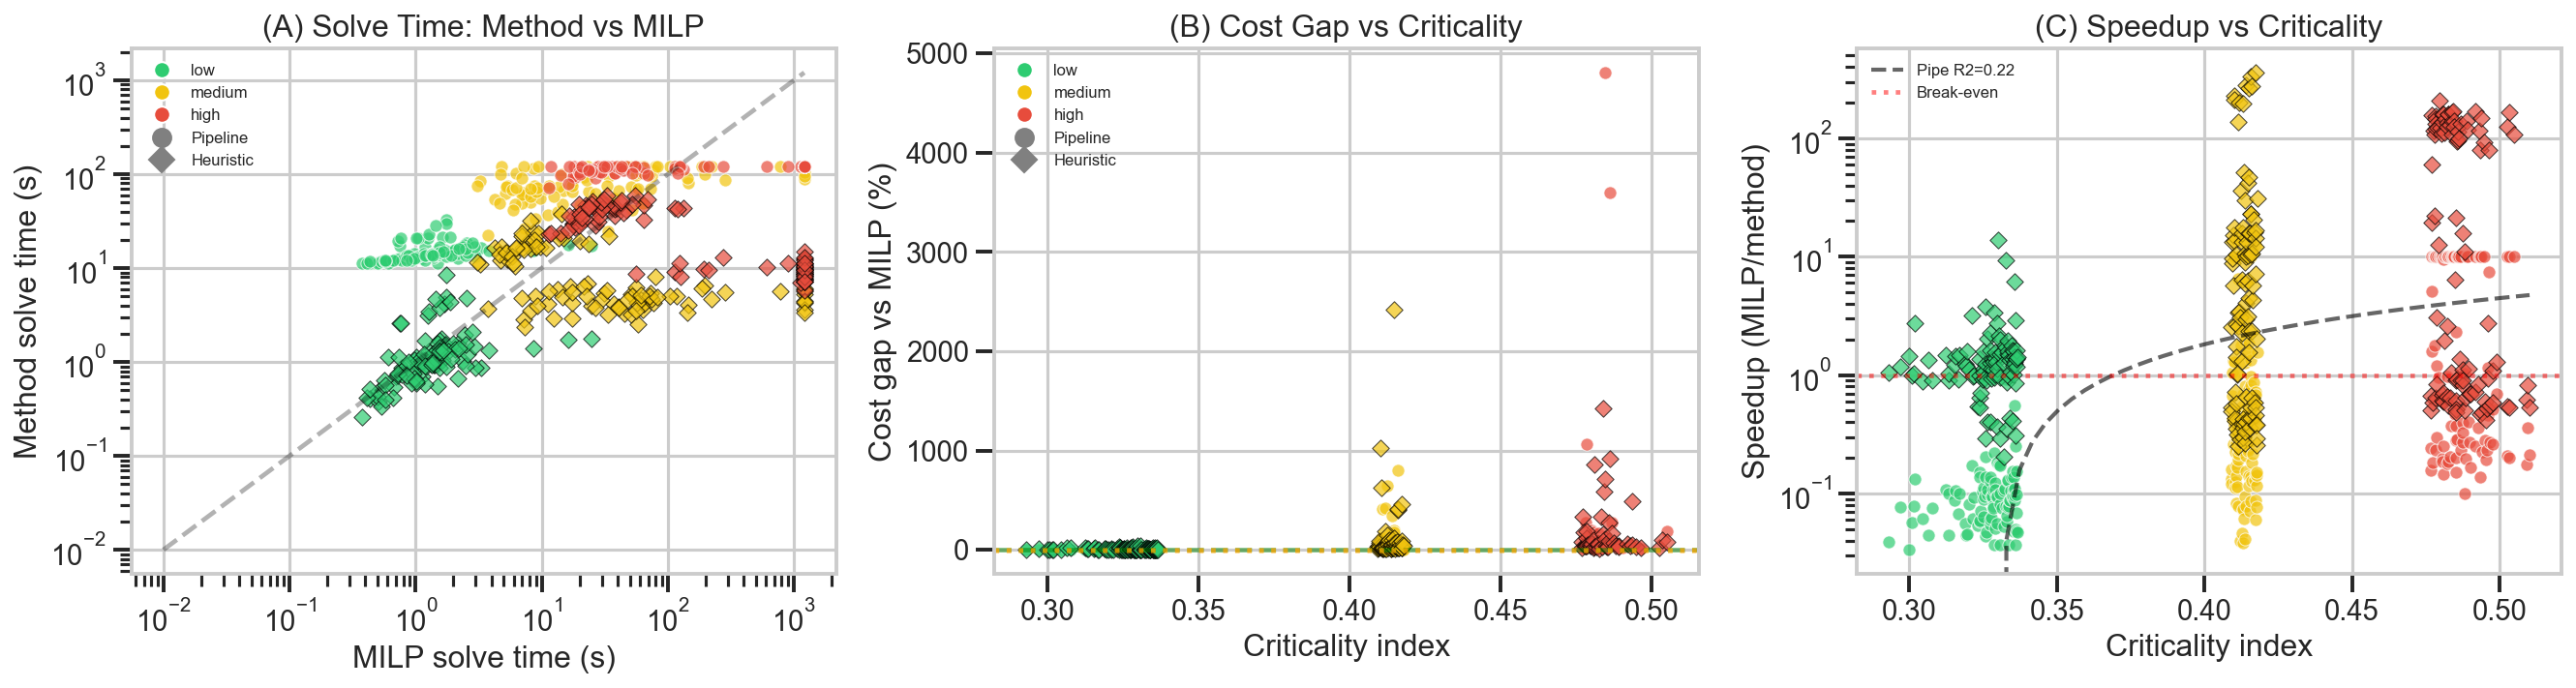

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (A) Solve time scatter
ax = axes[0]
for fam, color in FAMILY_COLORS.items():
    m = df['family'] == fam
    ax.scatter(df.loc[m, 'milp_solve_time'], df.loc[m, 'pipeline_solve_time'],
               c=color, marker='o', s=40, alpha=0.7, edgecolors='white', linewidth=0.5)
    if HAS_HEURISTIC:
        ax.scatter(df.loc[m, 'milp_solve_time'], df.loc[m, 'heur_solve_time'],
                   c=color, marker='D', s=35, alpha=0.7, edgecolors='black', linewidth=0.5)
mx = max(df['milp_solve_time'].max(), df['pipeline_solve_time'].max())
ax.plot([1e-2, mx], [1e-2, mx], 'k--', alpha=0.3)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('MILP solve time (s)'); ax.set_ylabel('Method solve time (s)')
ax.set_title('(A) Solve Time: Method vs MILP')
fam_handles = [Line2D([0],[0], marker='o', color='w', markerfacecolor=c, markersize=8, label=f) for f,c in FAMILY_COLORS.items()]
method_handles = [Line2D([0],[0], marker='o', color='gray', linestyle='', label='Pipeline')]
if HAS_HEURISTIC:
    method_handles.append(Line2D([0],[0], marker='D', color='gray', linestyle='', label='Heuristic'))
ax.legend(handles=fam_handles + method_handles, fontsize=8, loc='upper left')

# (B) Cost gap vs criticality
ax = axes[1]
for fam, color in FAMILY_COLORS.items():
    m = df['family'] == fam
    ax.scatter(df.loc[m, 'criticality_index'], df.loc[m, 'cost_gap_pct'],
               c=color, marker='o', s=40, alpha=0.7, edgecolors='white', linewidth=0.5)
    if HAS_HEURISTIC:
        ax.scatter(df.loc[m, 'criticality_index'], df.loc[m, 'heur_cost_gap_pct'],
                   c=color, marker='D', s=35, alpha=0.7, edgecolors='black', linewidth=0.5)
ax.axhline(0, color='green', linestyle='--', alpha=0.5)
ax.axhline(5, color='orange', linestyle=':', alpha=0.5)
ax.axhline(-5, color='orange', linestyle=':', alpha=0.5)
ax.set_xlabel('Criticality index'); ax.set_ylabel('Cost gap vs MILP (%)')
ax.set_title('(B) Cost Gap vs Criticality')
ax.legend(handles=fam_handles + method_handles, fontsize=8, loc='upper left')

# (C) Speedup vs criticality
ax = axes[2]
for fam, color in FAMILY_COLORS.items():
    m = df['family'] == fam
    ax.scatter(df.loc[m, 'criticality_index'], df.loc[m, 'speedup'],
               c=color, marker='o', s=40, alpha=0.7, edgecolors='white', linewidth=0.5)
    if HAS_HEURISTIC:
        ax.scatter(df.loc[m, 'criticality_index'], df.loc[m, 'heur_speedup'],
                   c=color, marker='D', s=35, alpha=0.7, edgecolors='black', linewidth=0.5)
valid = df.dropna(subset=['criticality_index', 'speedup'])
valid = valid[valid['speedup'] > 0]
if len(valid) > 3:
    slope, intercept, r_val, p_val, _ = stats.linregress(valid['criticality_index'], valid['speedup'])
    x_line = np.linspace(valid['criticality_index'].min(), valid['criticality_index'].max(), 50)
    ax.plot(x_line, slope * x_line + intercept, 'k--', lw=2, alpha=0.6,
            label=f'Pipe R2={r_val**2:.2f}')
ax.axhline(1, color='red', linestyle=':', alpha=0.5, label='Break-even')
ax.set_xlabel('Criticality index'); ax.set_ylabel('Speedup (MILP/method)')
ax.set_yscale('log'); ax.set_title('(C) Speedup vs Criticality')
ax.legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig1_solve_time_cost_gap_speedup.png', dpi=300, bbox_inches='tight')
plt.show()


## 11. Stage Distribution and Speedup Boxplot

C:\Users\coudr\AppData\Local\Temp\ipykernel_19316\2246508421.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_boxes, labels=['Low', 'Medium', 'High'], patch_artist=True, showmeans=True)


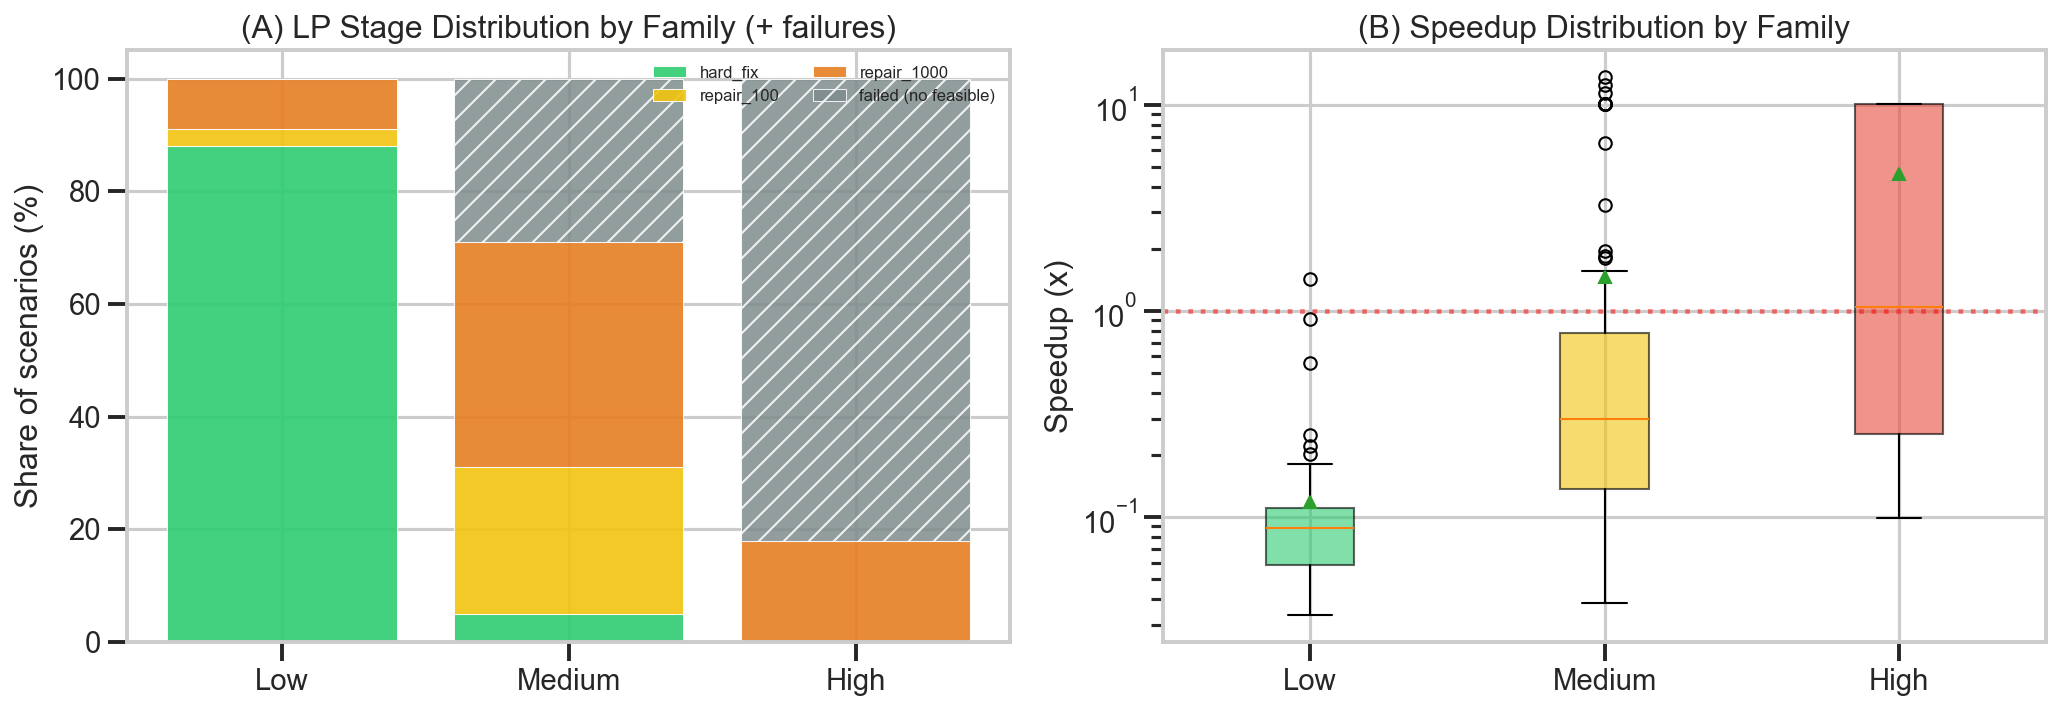

Pipeline failure rate by family:
  low   : 0/100 (0.0%)
  medium: 29/100 (29.0%)
  high  : 82/100 (82.0%)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (A) Stacked stage distribution by family (success-vs-failure included)
ax = axes[0]
families_list = ['low', 'medium', 'high']
x = np.arange(len(families_list))
bottom = np.zeros(len(families_list))
stage_col = 'pipeline_stage_reached' if 'pipeline_stage_reached' in df.columns else 'pipeline_stage'

# Successful stages first, then a "failed" segment.
for stage_internal, stage_disp in zip(PIPELINE_STAGES, PIPELINE_STAGES_DISPLAY):
    vals = []
    for fam in families_list:
        fam_df = df[df['family'] == fam]
        n_total = max(len(fam_df), 1)
        n_stage = ((fam_df[stage_col] == stage_internal) & fam_df['success'].astype(bool)).sum()
        vals.append(n_stage / n_total * 100.0)
    vals = np.array(vals)
    ax.bar(x, vals, bottom=bottom, label=stage_disp,
           color=STAGE_COLORS.get(stage_disp, 'gray'), alpha=0.9, edgecolor='white', linewidth=0.5)
    bottom += vals

# Failed share = scenarios where the pipeline did not find a feasible solution.
failed_vals = []
for fam in families_list:
    fam_df = df[df['family'] == fam]
    n_total = max(len(fam_df), 1)
    n_failed = (~fam_df['success'].astype(bool)).sum()
    failed_vals.append(n_failed / n_total * 100.0)
failed_vals = np.array(failed_vals)
ax.bar(x, failed_vals, bottom=bottom, label='failed (no feasible)',
       color=STAGE_COLORS['failed'], alpha=0.85, edgecolor='white', linewidth=0.5, hatch='//')

ax.set_xticks(x)
ax.set_xticklabels(['Low', 'Medium', 'High'])
ax.set_ylabel('Share of scenarios (%)')
ax.set_ylim(0, 105)
ax.set_title('(A) LP Stage Distribution by Family (+ failures)')
ax.legend(fontsize=8, ncol=2, loc='upper right')

# (B) Speedup boxplot by family
ax = axes[1]
data_boxes = [df[df['family'] == fam]['speedup'].dropna() for fam in families_list]
bp = ax.boxplot(data_boxes, labels=['Low', 'Medium', 'High'], patch_artist=True, showmeans=True)
for patch, fam in zip(bp['boxes'], families_list):
    patch.set_facecolor(FAMILY_COLORS[fam]); patch.set_alpha(0.6)
ax.set_ylabel('Speedup (x)')
ax.set_title('(B) Speedup Distribution by Family')
ax.set_yscale('log')
ax.axhline(1, color='red', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig2_stage_distribution_speedup.png', dpi=300, bbox_inches='tight')
plt.show()

print('Pipeline failure rate by family:')
for fam in families_list:
    fam_df = df[df['family'] == fam]
    nf = (~fam_df['success'].astype(bool)).sum()
    print(f"  {fam:6s}: {nf}/{len(fam_df)} ({nf/max(len(fam_df),1)*100:.1f}%)")


## 12. Pareto Frontier: Quality vs Speed

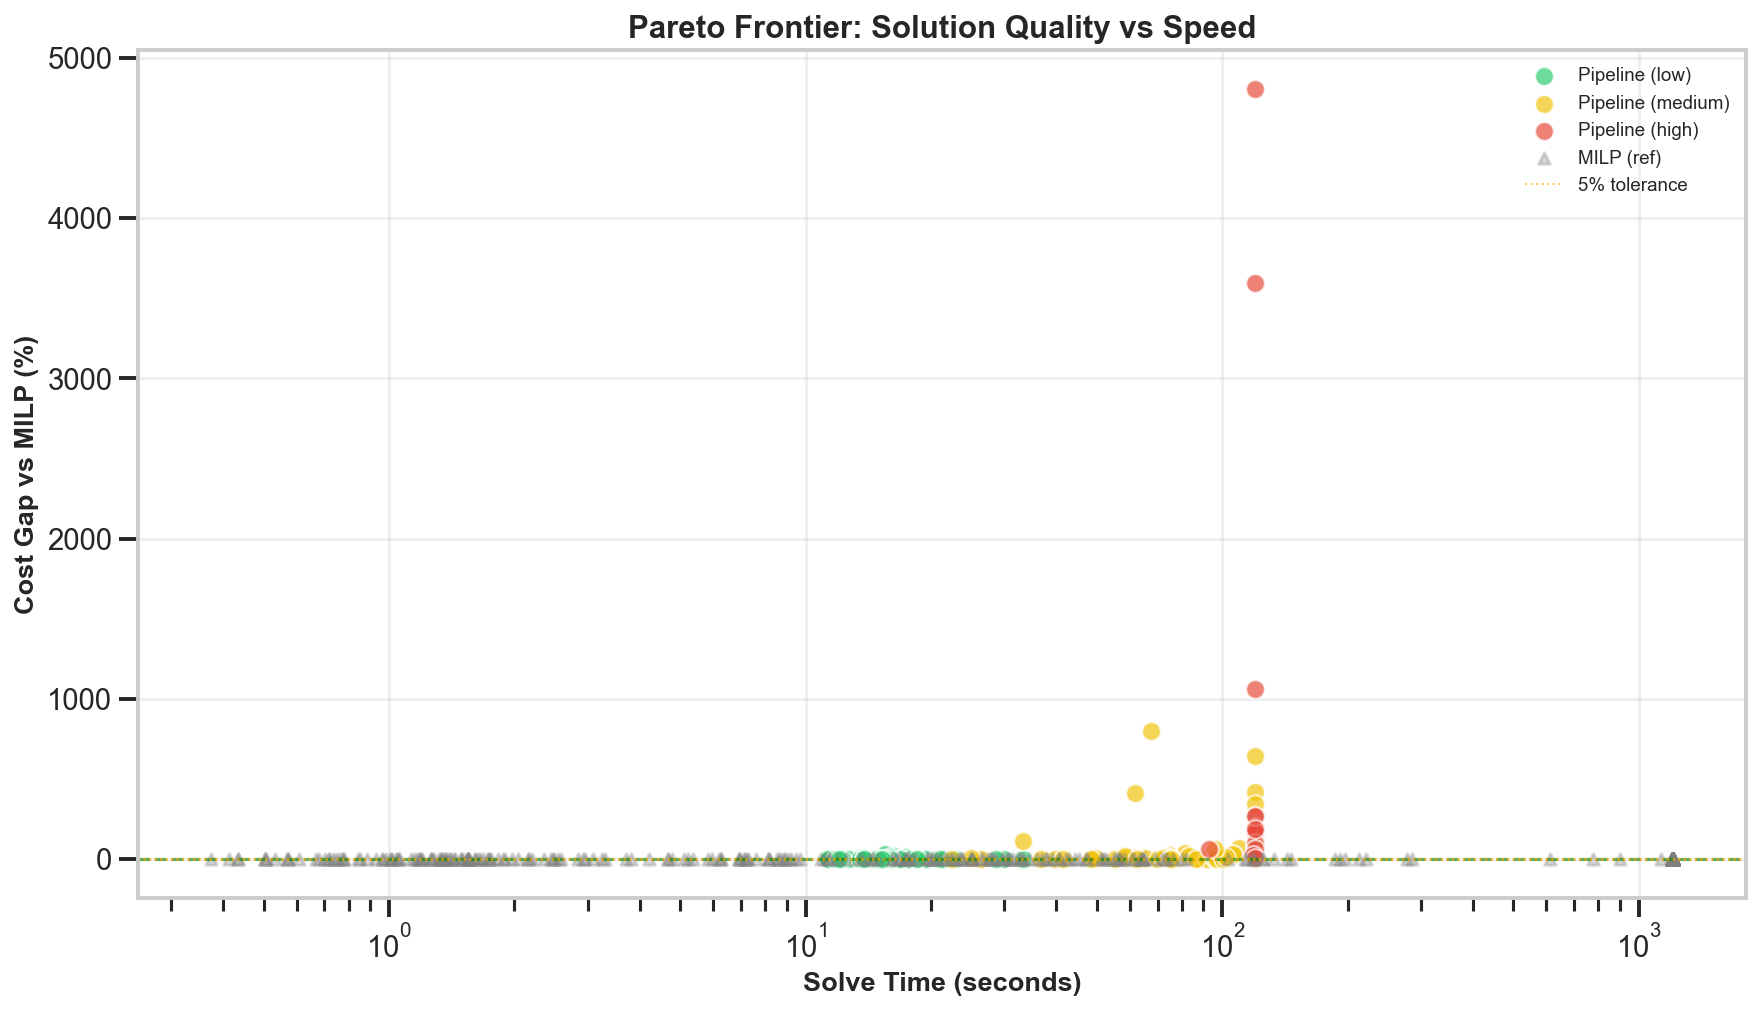

Pareto-optimal (|gap|<5%, time<120s): 117/300


In [12]:
fig, ax = plt.subplots(figsize=(12, 7))
for fam, color in FAMILY_COLORS.items():
    m = df['family'] == fam
    ax.scatter(df.loc[m, 'pipeline_solve_time'], df.loc[m, 'cost_gap_pct'],
              c=color, label=f'Pipeline ({fam})', s=80, alpha=0.7, edgecolors='white', linewidth=1)
ax.scatter(df['milp_solve_time'], [0]*len(df), c='gray', label='MILP (ref)', s=30, alpha=0.3, marker='^')

ax.axhline(0, color='green', linestyle='--', lw=1.5, alpha=0.6)
ax.axhline(5, color='orange', linestyle=':', lw=1, alpha=0.6, label='5% tolerance')
ax.axhline(-5, color='orange', linestyle=':', lw=1, alpha=0.6)
ax.set_xlabel('Solve Time (seconds)', fontsize=13, fontweight='bold')
ax.set_ylabel('Cost Gap vs MILP (%)', fontsize=13, fontweight='bold')
ax.set_title('Pareto Frontier: Solution Quality vs Speed', fontsize=15, fontweight='bold')
ax.set_xscale('log')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig3_pareto_quality_speed.png', dpi=300, bbox_inches='tight')
plt.show()

pareto = (df['cost_gap_pct'].abs() < 5) & (df['pipeline_solve_time'] < 120)
print(f'Pareto-optimal (|gap|<5%, time<120s): {pareto.sum()}/{len(df)}')


## 13. Economic Advantage Indicator

For each scenario:
$$\text{Total Cost}_{\text{method}} = C_{\text{solution}} + \lambda \cdot T_{\text{solve}}$$
$$\text{Advantage} = \text{Total Cost}_{\text{MILP}} - \text{Total Cost}_{\text{Pipeline}}$$


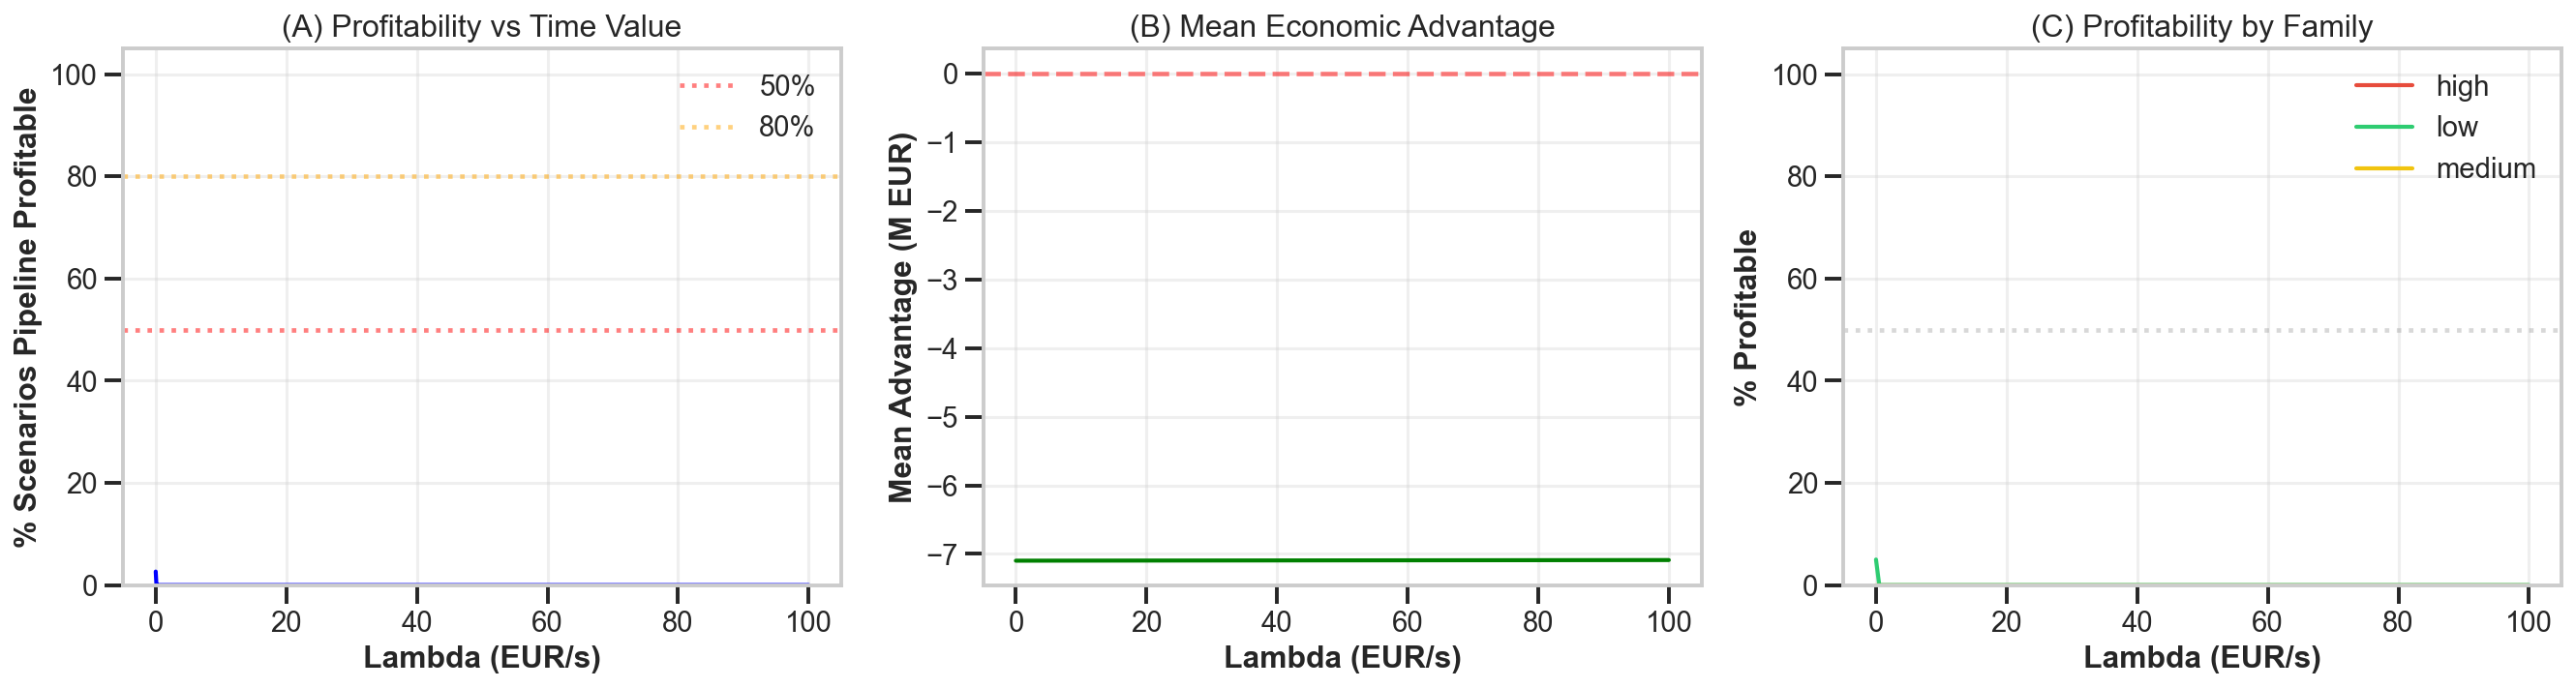

In [13]:
econ = EconomicAdvantageAnalyzer(df)
sensitivity_df = econ.sensitivity_analysis()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
ax.plot(sensitivity_df['lambda'], sensitivity_df['pct_profitable'], 'b-', lw=2)
ax.axhline(50, color='red', linestyle=':', alpha=0.5, label='50%')
ax.axhline(80, color='orange', linestyle=':', alpha=0.5, label='80%')
ax.set_xlabel('Lambda (EUR/s)', fontweight='bold')
ax.set_ylabel('% Scenarios Pipeline Profitable', fontweight='bold')
ax.set_title('(A) Profitability vs Time Value')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_ylim(0, 105)

ax = axes[1]
ax.plot(sensitivity_df['lambda'], sensitivity_df['mean_advantage'] / 1e6, 'g-', lw=2)
ax.axhline(0, color='red', linestyle='--', alpha=0.5)
ax.set_xlabel('Lambda (EUR/s)', fontweight='bold')
ax.set_ylabel('Mean Advantage (M EUR)', fontweight='bold')
ax.set_title('(B) Mean Economic Advantage'); ax.grid(True, alpha=0.3)

ax = axes[2]
family_sens = econ.sensitivity_by_family()
for fam_name, fam_df in family_sens.items():
    color = FAMILY_COLORS.get(fam_name, 'gray')
    ax.plot(fam_df['lambda'], fam_df['pct_profitable'], '-', color=color, lw=2, label=fam_name)
ax.axhline(50, color='gray', linestyle=':', alpha=0.3)
ax.set_xlabel('Lambda (EUR/s)', fontweight='bold')
ax.set_ylabel('% Profitable', fontweight='bold')
ax.set_title('(C) Profitability by Family')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_ylim(0, 105)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig4_economic_advantage.png', dpi=300, bbox_inches='tight')
plt.show()


## 14. Breakeven Lambda Analysis

In [14]:
summary = econ.compute_summary(lambda_values=[1, 5, 10, 20, 50, 100])

print('=' * 60)
print('ECONOMIC ADVANTAGE SUMMARY')
print('=' * 60)
print(f"Breakeven lambda (50% profitable): {summary['breakeven_lambda_50pct']:.2f} EUR/s")
print(f"Breakeven lambda (80% profitable): {summary['breakeven_lambda_80pct']:.2f} EUR/s")
print(f"Breakeven lambda (95% profitable): {summary['breakeven_lambda_95pct']:.2f} EUR/s")
print(f"\nPer-family breakeven (50%):")
for fam, lam in summary['family_breakevens'].items():
    print(f"  {fam}: {lam:.2f} EUR/s")
print(f"\nAt selected lambda values:")
for key, val in summary.items():
    if key.startswith('lambda_'):
        lam = key.replace('lambda_', '')
        print(f"  lambda={lam} EUR/s: {val['pct_profitable']:.1f}% profitable, "
              f"mean advantage={val['mean_advantage_eur']/1e6:.2f} MEUR")


ECONOMIC ADVANTAGE SUMMARY
Breakeven lambda (50% profitable): inf EUR/s
Breakeven lambda (80% profitable): inf EUR/s
Breakeven lambda (95% profitable): inf EUR/s

Per-family breakeven (50%):
  high: inf EUR/s
  low: inf EUR/s
  medium: inf EUR/s

At selected lambda values:
  lambda=1 EUR/s: 0.0% profitable, mean advantage=-7.10 MEUR
  lambda=5 EUR/s: 0.0% profitable, mean advantage=-7.10 MEUR
  lambda=10 EUR/s: 0.0% profitable, mean advantage=-7.10 MEUR
  lambda=20 EUR/s: 0.0% profitable, mean advantage=-7.10 MEUR
  lambda=50 EUR/s: 0.0% profitable, mean advantage=-7.09 MEUR
  lambda=100 EUR/s: 0.0% profitable, mean advantage=-7.09 MEUR


## 15. Lambda Sensitivity Heatmap

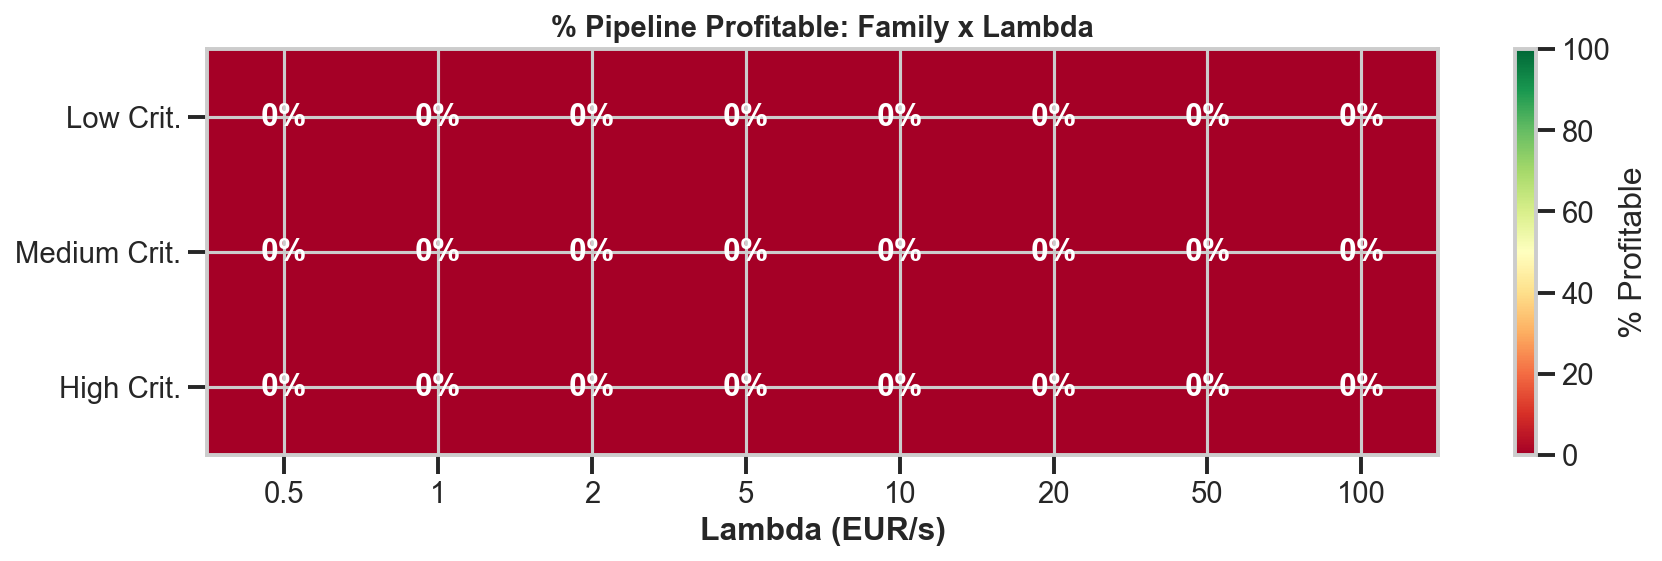

In [15]:
lambda_values = [0.5, 1, 2, 5, 10, 20, 50, 100]
families_list = ['low', 'medium', 'high']

heat_data = np.zeros((len(families_list), len(lambda_values)))
for i, fam in enumerate(families_list):
    sub_df = df[df['family'] == fam]
    sub_econ = EconomicAdvantageAnalyzer(sub_df)
    for j, lam in enumerate(lambda_values):
        adv_df = sub_econ.compute_advantage(lam)
        valid = adv_df.dropna(subset=['advantage'])
        heat_data[i, j] = valid['pipeline_profitable'].mean() * 100 if len(valid) else np.nan

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(heat_data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=100)
ax.set_xticks(range(len(lambda_values)))
ax.set_xticklabels([f'{l}' for l in lambda_values])
ax.set_yticks(range(len(families_list)))
ax.set_yticklabels(['Low Crit.', 'Medium Crit.', 'High Crit.'])
ax.set_xlabel('Lambda (EUR/s)', fontweight='bold')
ax.set_title('% Pipeline Profitable: Family x Lambda', fontsize=14, fontweight='bold')

for i in range(len(families_list)):
    for j in range(len(lambda_values)):
        val = heat_data[i, j]
        color = 'white' if (val < 30 or val > 70) else 'black'
        ax.text(j, i, f'{val:.0f}%', ha='center', va='center', color=color, fontweight='bold')

plt.colorbar(im, ax=ax, label='% Profitable')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig5_lambda_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


## 16. Cumulative Time Savings

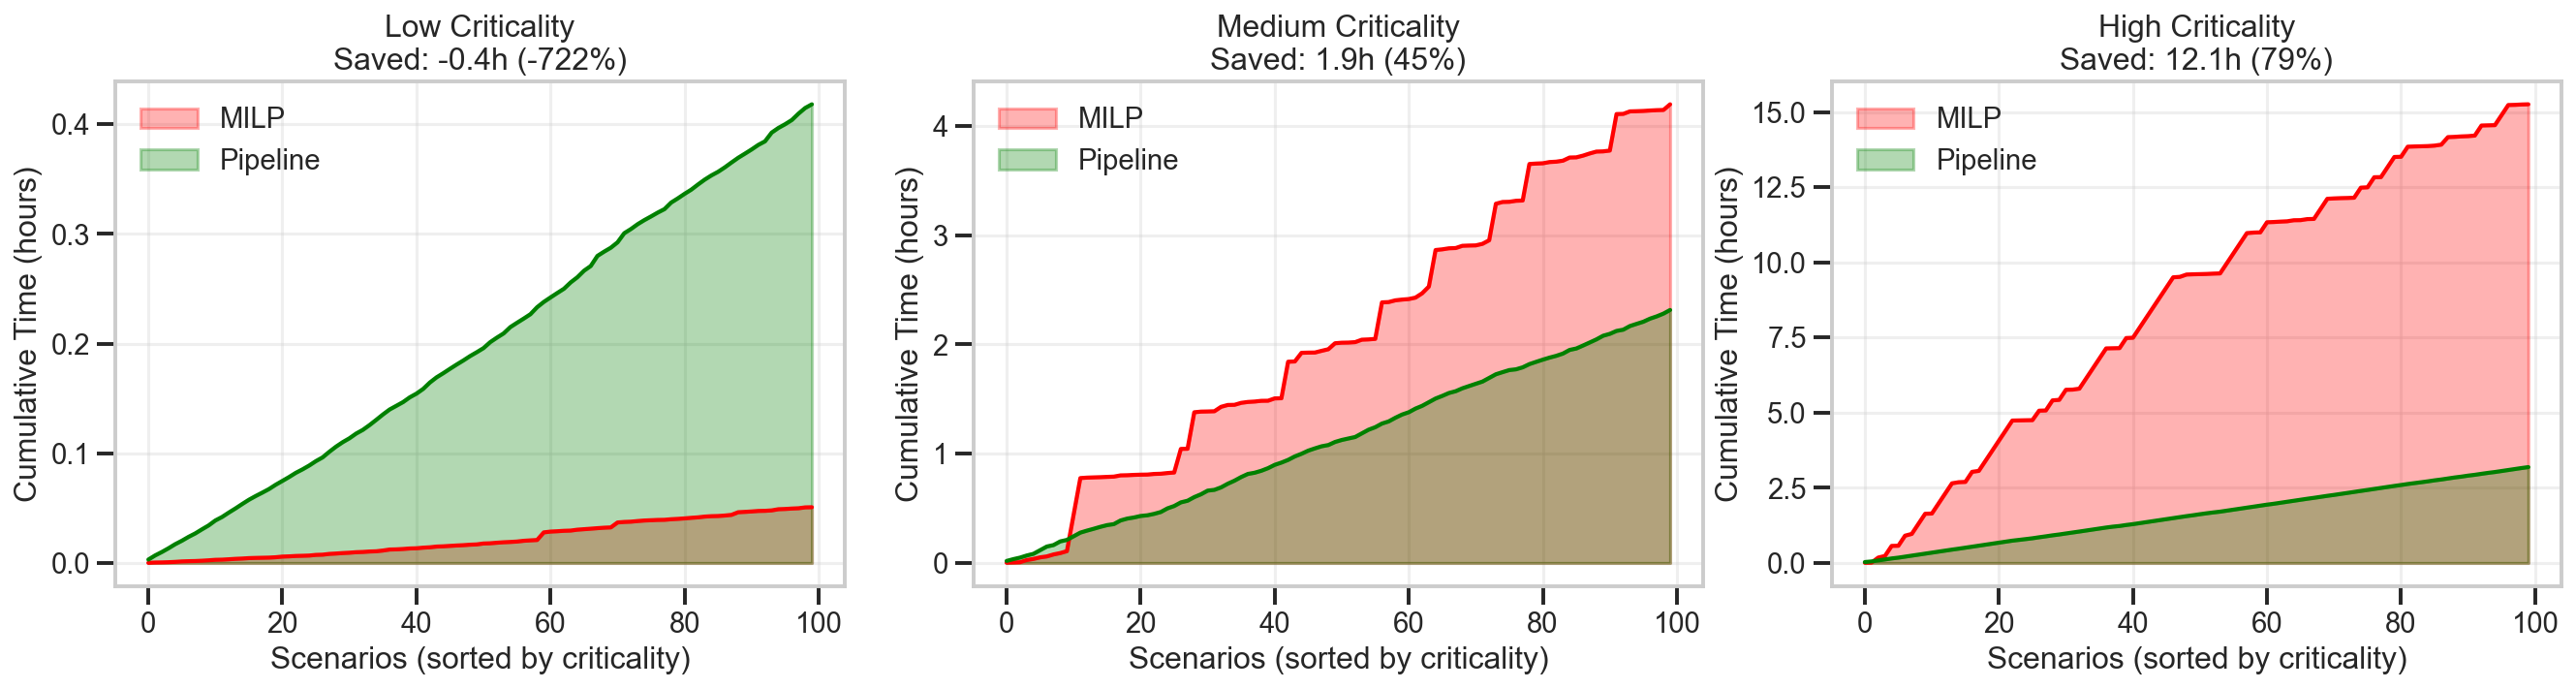

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, fam in enumerate(families_list):
    ax = axes[idx]
    fam_df = df[df['family'] == fam].sort_values('criticality_index').reset_index(drop=True)
    cum_milp = fam_df['milp_solve_time'].cumsum() / 3600
    cum_pipe = fam_df['pipeline_solve_time'].cumsum() / 3600
    ax.fill_between(range(len(fam_df)), cum_milp, alpha=0.3, color='red', label='MILP')
    ax.fill_between(range(len(fam_df)), cum_pipe, alpha=0.3, color='green', label='Pipeline')
    ax.plot(range(len(fam_df)), cum_milp, 'r-', lw=2)
    ax.plot(range(len(fam_df)), cum_pipe, 'g-', lw=2)
    total_milp = cum_milp.iloc[-1] if len(cum_milp) > 0 else 0
    total_pipe = cum_pipe.iloc[-1] if len(cum_pipe) > 0 else 0
    saved = total_milp - total_pipe
    pct_saved = saved / max(total_milp, 1e-9) * 100
    ax.set_xlabel('Scenarios (sorted by criticality)')
    ax.set_ylabel('Cumulative Time (hours)')
    ax.set_title(f'{fam.capitalize()} Criticality\nSaved: {saved:.1f}h ({pct_saved:.0f}%)')
    ax.legend(loc='upper left'); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig6_cumulative_time.png', dpi=300, bbox_inches='tight')
plt.show()


## 17. Pipeline Timing Breakdown

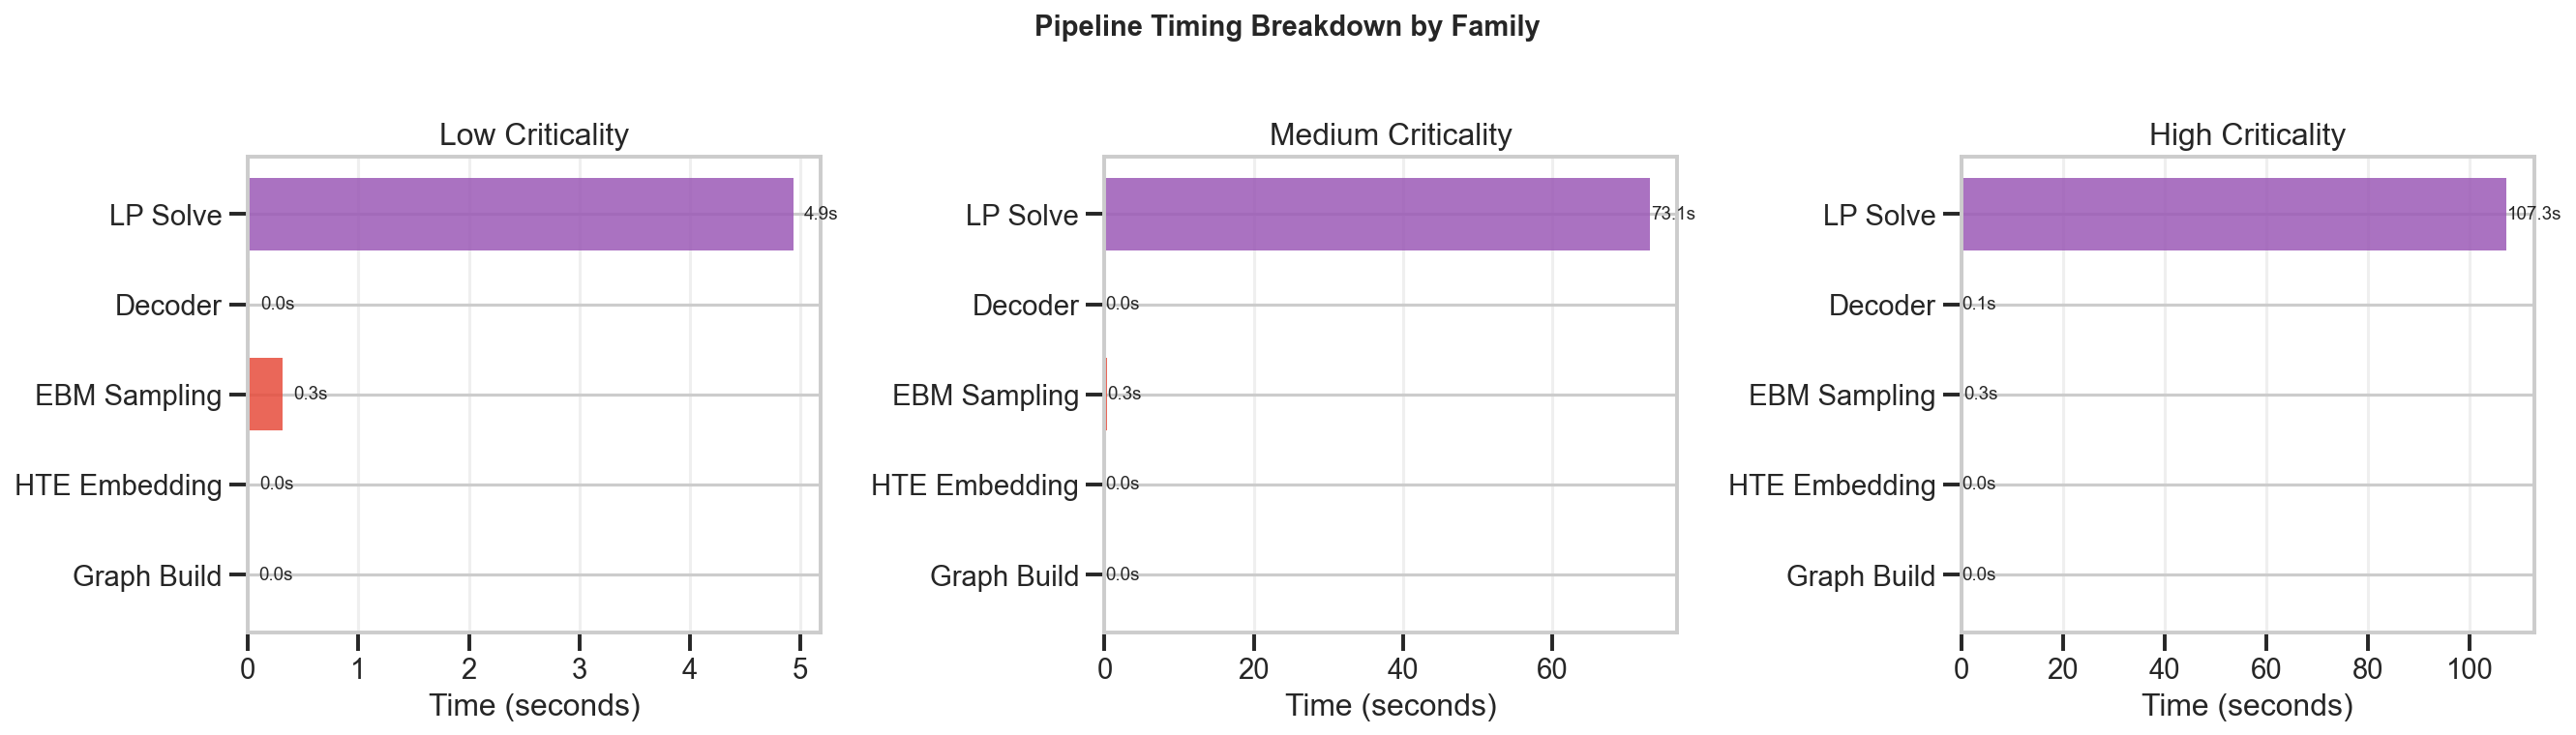

In [17]:
timing_cols = ['time_graph_build', 'time_embedding', 'time_ebm_sampling', 'time_decoder', 'time_lp_solve']
timing_labels = ['Graph Build', 'HTE Embedding', 'EBM Sampling', 'Decoder', 'LP Solve']
timing_colors = ['#3498db', '#2ecc71', '#e74c3c', '#f1c40f', '#9b59b6']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, fam in enumerate(families_list):
    ax = axes[idx]
    fam_df = df[df['family'] == fam]
    means = [fam_df[col].mean() if col in fam_df.columns else 0.0 for col in timing_cols]
    ax.barh(timing_labels, means, color=timing_colors, alpha=0.85)
    for i, v in enumerate(means):
        ax.text(v + 0.1, i, f'{v:.1f}s', va='center', fontsize=9)
    ax.set_xlabel('Time (seconds)')
    ax.set_title(f'{fam.capitalize()} Criticality')
    ax.grid(True, alpha=0.3, axis='x')

fig.suptitle('Pipeline Timing Breakdown by Family', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig7_timing_breakdown.png', dpi=300, bbox_inches='tight')
plt.show()


## 18. Criticality Index Distribution and Complexity

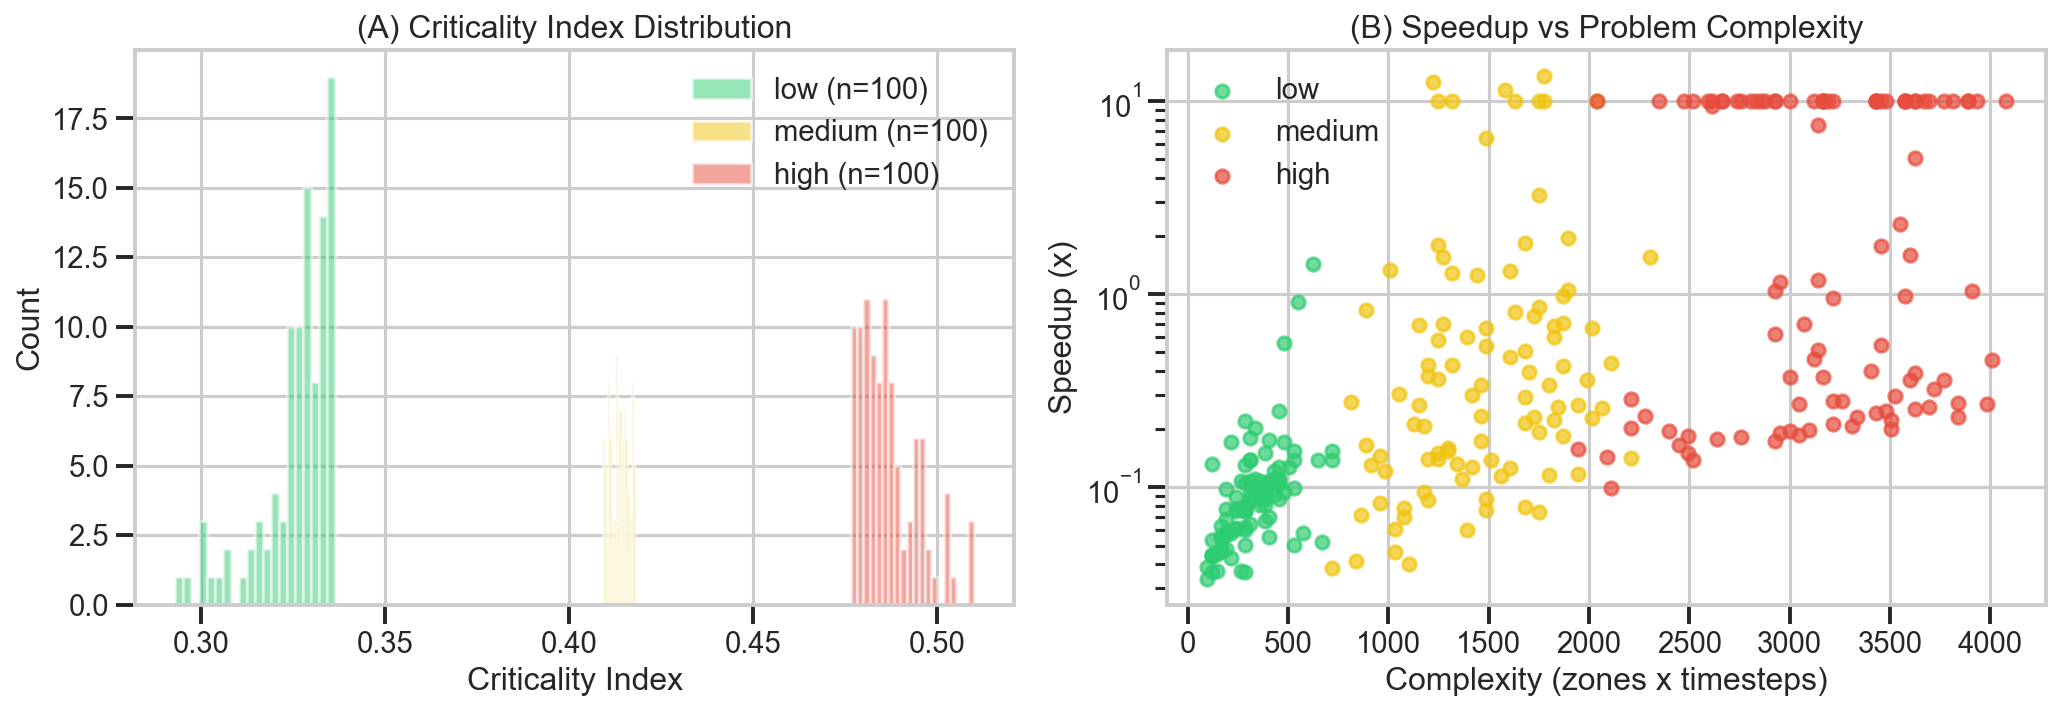

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for fam, color in FAMILY_COLORS.items():
    fam_df = df[df['family'] == fam]
    ax.hist(fam_df['criticality_index'], bins=20, alpha=0.5, color=color,
            label=f'{fam} (n={len(fam_df)})', edgecolor='white')
ax.set_xlabel('Criticality Index'); ax.set_ylabel('Count')
ax.set_title('(A) Criticality Index Distribution')
ax.legend()

ax = axes[1]
df['complexity'] = df['n_zones'] * df['n_timesteps']
for fam, color in FAMILY_COLORS.items():
    m = df['family'] == fam
    ax.scatter(df.loc[m, 'complexity'], df.loc[m, 'speedup'],
              c=color, label=fam, s=40, alpha=0.7)
ax.set_xlabel('Complexity (zones x timesteps)'); ax.set_ylabel('Speedup (x)')
ax.set_yscale('log'); ax.set_title('(B) Speedup vs Problem Complexity')
ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig8_criticality_complexity.png', dpi=300, bbox_inches='tight')
plt.show()


## 19. Final Summary Table (Pipeline + Heuristic + MILP)

In [19]:
def _build_row(name, sub_df):
    valid_p = sub_df.dropna(subset=['speedup', 'cost_gap_pct'])
    valid_h = sub_df.dropna(subset=['heur_speedup', 'heur_cost_gap_pct']) if HAS_HEURISTIC else sub_df.iloc[0:0]
    stage_col = 'pipeline_stage_reached' if 'pipeline_stage_reached' in sub_df.columns else 'pipeline_stage'
    return {
        'Family': name,
        'N': len(sub_df),
        'Crit. Index': f"{sub_df['criticality_index'].mean():.3f}",
        'Pipe Success':       f"{sub_df['success'].mean()*100:.0f}%",
        'Pipe Speedup (med)': f"{valid_p['speedup'].median():.1f}x"      if len(valid_p) else 'N/A',
        'Pipe Gap P50':       f"{valid_p['cost_gap_pct'].median():.1f}%" if len(valid_p) else 'N/A',
        'Pipe Gap P90':       f"{np.percentile(valid_p['cost_gap_pct'], 90):.1f}%" if len(valid_p) else 'N/A',
        'Pipe Gap P99':       f"{np.percentile(valid_p['cost_gap_pct'], 99):.1f}%" if len(valid_p) else 'N/A',
        'Pipe Time (mean)':   f"{sub_df['pipeline_solve_time'].mean():.1f}s",
        'Hard Fix %':         f"{((sub_df[stage_col]=='hard_fix') & sub_df['success'].astype(bool)).mean()*100:.0f}%",
        'Heur Success':       f"{sub_df['heur_success'].mean()*100:.0f}%"          if HAS_HEURISTIC and sub_df['heur_success'].notna().any() else 'N/A',
        'Heur Speedup (med)': f"{valid_h['heur_speedup'].median():.1f}x"           if len(valid_h) else 'N/A',
        'Heur Gap P50':       f"{valid_h['heur_cost_gap_pct'].median():.1f}%"      if len(valid_h) else 'N/A',
        'Heur Gap P90':       f"{np.percentile(valid_h['heur_cost_gap_pct'], 90):.1f}%" if len(valid_h) else 'N/A',
        'Heur Gap P99':       f"{np.percentile(valid_h['heur_cost_gap_pct'], 99):.1f}%" if len(valid_h) else 'N/A',
        'Heur Time (mean)':   f"{sub_df['heur_solve_time'].mean():.1f}s"           if HAS_HEURISTIC and sub_df['heur_solve_time'].notna().any() else 'N/A',
        'MILP Time (mean)':   f"{sub_df['milp_solve_time'].mean():.1f}s",
    }

summary_rows = [_build_row(fam.capitalize(), df[df['family'] == fam]) for fam in families_list]
summary_rows.append(_build_row('ALL', df))
summary_table = pd.DataFrame(summary_rows)
print('\n' + '=' * 120)
print('FINAL EVALUATION SUMMARY: Pipeline (GNN+EBM v3 good) vs Heuristic vs MILP')
print('=' * 120)
with pd.option_context('display.max_columns', None, 'display.width', 200):
    print(summary_table.to_string(index=False))

summary_table.to_csv(OUTPUT_DIR / 'summary_table.csv', index=False)
df.to_csv(OUTPUT_DIR / 'full_comparison.csv', index=False)
print(f'\nResults saved to {OUTPUT_DIR}')



FINAL EVALUATION SUMMARY: Pipeline (GNN+EBM v3 good) vs Heuristic vs MILP
Family   N Crit. Index Pipe Success Pipe Speedup (med) Pipe Gap P50 Pipe Gap P90 Pipe Gap P99 Pipe Time (mean) Hard Fix % Heur Success Heur Speedup (med) Heur Gap P50 Heur Gap P90 Heur Gap P99 Heur Time (mean) MILP Time (mean)
   Low 100       0.326         100%               0.1x         0.2%         4.8%        23.3%            15.1s        88%          99%               1.2x         3.7%        22.3%         inf%             1.4s             1.8s
Medium 100       0.414          71%               0.3x        21.3%         nan%         nan%            83.3s         5%          66%               4.2x        71.8%         nan%         nan%             9.2s           151.1s
  High 100       0.487          18%               1.0x         inf%         nan%         nan%           114.8s         0%          51%               8.8x      1170.3%         nan%         nan%            24.6s           549.3s
   ALL 300       

c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in scalar subtract
  diff_b_a = b - a
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in scalar subtract
  diff_b_a = b - a
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in scalar subtract
  diff_b_a = b - a
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in scalar subtract
  diff_b_a = b - a
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4596: RuntimeWarning: invalid value encountered in scalar subtract
  diff_b_a = b - a
c:\Users\coudr\OneDrive\projects\benchmark\.venv\Lib\site-packages\num

## 20. Focused Analysis: High-Criticality MaxTimeLimit Scenarios

The pipeline's value proposition is strongest on MILP-hard scenarios that hit the solver time limit.
This section isolates the **high-criticality MaxTimeLimit** subset and computes the same panels
as `evaluation_pipeline.ipynb`.

In [20]:
df_htl = df[(df['family'] == 'high') & (df['milp_termination'] == 'maxTimeLimit')].copy()
print(f"High-crit MaxTimeLimit scenarios: {len(df_htl)} / {len(df[df['family'] == 'high'])} high-crit total")
if len(df_htl):
    print(f"Pipeline solve time : mean={df_htl['pipeline_solve_time'].mean():.1f}s  "
          f"median={df_htl['pipeline_solve_time'].median():.1f}s")
    print(f"MILP solve time     : mean={df_htl['milp_solve_time'].mean():.1f}s")
    print(f"Speedup             : mean={df_htl['speedup'].mean():.1f}x  median={df_htl['speedup'].median():.1f}x")
    print(f"Pipeline success    : {df_htl['success'].mean()*100:.1f}%")


High-crit MaxTimeLimit scenarios: 41 / 100 high-crit total
Pipeline solve time : mean=120.0s  median=120.0s
MILP solve time     : mean=1205.6s
Speedup             : mean=10.0x  median=10.0x
Pipeline success    : 26.8%


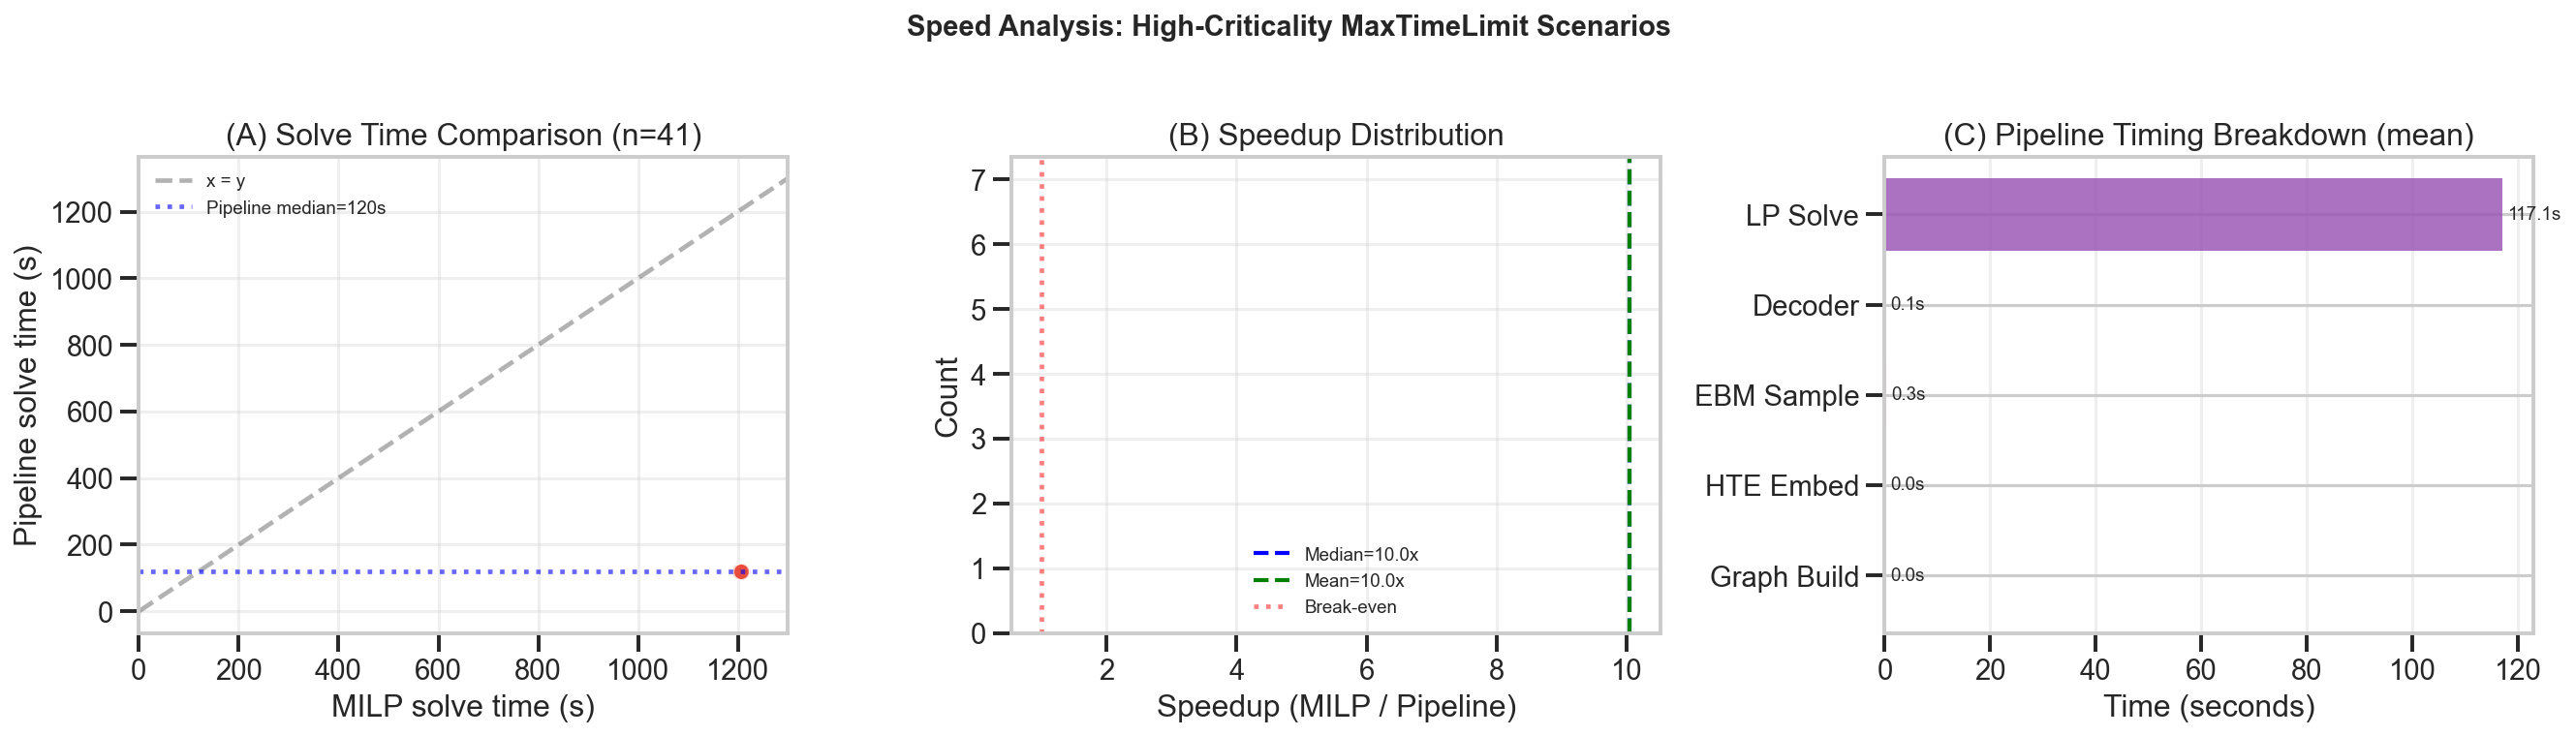

In [21]:
# Speed analysis (HTL subset)
if len(df_htl):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    ax = axes[0]
    ax.scatter(df_htl['milp_solve_time'], df_htl['pipeline_solve_time'],
               c='#e74c3c', s=60, alpha=0.7, edgecolors='white', linewidth=0.5)
    ax.plot([0, 1300], [0, 1300], 'k--', alpha=0.3, label='x = y')
    ax.axhline(df_htl['pipeline_solve_time'].median(), color='blue', linestyle=':', alpha=0.6,
               label=f"Pipeline median={df_htl['pipeline_solve_time'].median():.0f}s")
    ax.set_xlabel('MILP solve time (s)'); ax.set_ylabel('Pipeline solve time (s)')
    ax.set_title(f'(A) Solve Time Comparison (n={len(df_htl)})'); ax.legend(fontsize=9)
    ax.set_xlim(0, 1300); ax.grid(True, alpha=0.3)

    ax = axes[1]
    ax.hist(df_htl['speedup'].dropna(), bins=20, color='#e74c3c', alpha=0.7, edgecolor='white')
    if df_htl['speedup'].notna().any():
        ax.axvline(df_htl['speedup'].median(), color='blue', linestyle='--', lw=2,
                   label=f"Median={df_htl['speedup'].median():.1f}x")
        ax.axvline(df_htl['speedup'].mean(), color='green', linestyle='--', lw=2,
                   label=f"Mean={df_htl['speedup'].mean():.1f}x")
    ax.axvline(1, color='red', linestyle=':', alpha=0.5, label='Break-even')
    ax.set_xlabel('Speedup (MILP / Pipeline)'); ax.set_ylabel('Count')
    ax.set_title('(B) Speedup Distribution'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

    ax = axes[2]
    timing_cols_2 = ['time_graph_build', 'time_embedding', 'time_ebm_sampling', 'time_decoder', 'time_lp_solve']
    timing_labels_2 = ['Graph Build', 'HTE Embed', 'EBM Sample', 'Decoder', 'LP Solve']
    timing_colors_2 = ['#3498db', '#2ecc71', '#e74c3c', '#f1c40f', '#9b59b6']
    means = [df_htl[col].mean() for col in timing_cols_2]
    bars = ax.barh(timing_labels_2, means, color=timing_colors_2, alpha=0.85)
    for bar, v in zip(bars, means):
        ax.text(v + 1, bar.get_y() + bar.get_height()/2, f'{v:.1f}s', va='center', fontsize=9)
    ax.set_xlabel('Time (seconds)'); ax.set_title('(C) Pipeline Timing Breakdown (mean)')
    ax.grid(True, alpha=0.3, axis='x')
    fig.suptitle('Speed Analysis: High-Criticality MaxTimeLimit Scenarios', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig9_htl_speed_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print('No high-criticality MaxTimeLimit scenarios in this run.')


ValueError: supplied range of [28.672530357649833, inf] is not finite

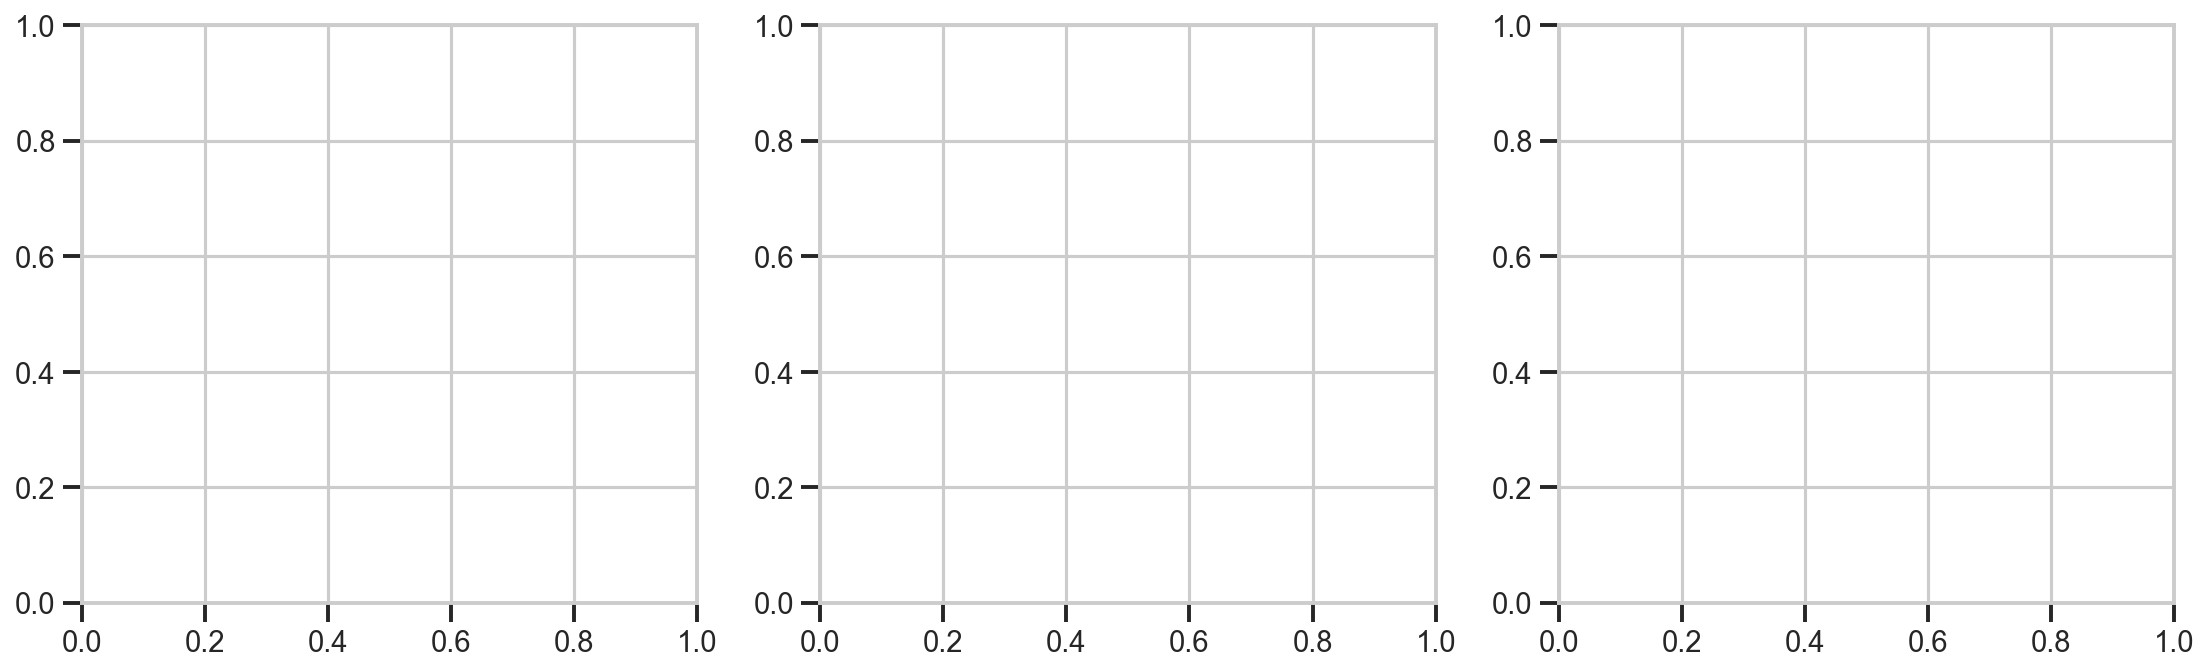

In [22]:
# Cost gap analysis (HTL subset)
if len(df_htl):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    ax = axes[0]
    valid_htl = df_htl.dropna(subset=['cost_gap_pct'])
    ax.hist(valid_htl['cost_gap_pct'], bins=25, color='#e74c3c', alpha=0.7, edgecolor='white')
    ax.axvline(0, color='green', linestyle='--', lw=2, label='No gap')
    if len(valid_htl):
        ax.axvline(valid_htl['cost_gap_pct'].median(), color='blue', linestyle='--', lw=2,
                   label=f"Median={valid_htl['cost_gap_pct'].median():.1f}%")
    ax.set_xlabel('Cost Gap vs MILP (%)'); ax.set_ylabel('Count')
    ax.set_title('(A) Cost Gap Distribution'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

    ax = axes[1]
    sc = ax.scatter(df_htl['n_zones'], df_htl['cost_gap_pct'],
                    c=df_htl['speedup'], cmap='RdYlGn', s=60, alpha=0.8,
                    edgecolors='white', linewidth=0.5)
    ax.axhline(0, color='green', linestyle='--', alpha=0.5)
    ax.set_xlabel('Number of Zones'); ax.set_ylabel('Cost Gap (%)')
    ax.set_title('(B) Cost Gap vs Problem Size')
    plt.colorbar(sc, ax=ax, label='Speedup (x)'); ax.grid(True, alpha=0.3)

    ax = axes[2]
    ax.scatter(df_htl['milp_objective'] / 1e6, df_htl['pipeline_objective'] / 1e6,
               c='#e74c3c', s=60, alpha=0.7, edgecolors='white', linewidth=0.5)
    finite_mask = df_htl[['milp_objective', 'pipeline_objective']].apply(np.isfinite).all(axis=1)
    if finite_mask.any():
        obj_min = min(df_htl.loc[finite_mask, 'milp_objective'].min(), df_htl.loc[finite_mask, 'pipeline_objective'].min()) / 1e6
        obj_max = max(df_htl.loc[finite_mask, 'milp_objective'].max(), df_htl.loc[finite_mask, 'pipeline_objective'].max()) / 1e6
        ax.plot([obj_min, obj_max], [obj_min, obj_max], 'k--', alpha=0.3, label='x = y')
    ax.set_xlabel('MILP Objective (M EUR)'); ax.set_ylabel('Pipeline Objective (M EUR)')
    ax.set_title('(C) Objective Comparison'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
    fig.suptitle('Cost Gap Analysis: High-Criticality MaxTimeLimit Scenarios', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig10_htl_cost_gap.png', dpi=300, bbox_inches='tight')
    plt.show()

    print('Cost gap stats (pipeline vs MILP best incumbent, HTL subset):')
    valid_htl = df_htl.dropna(subset=['cost_gap_pct'])
    if len(valid_htl):
        print(f"  Mean: {valid_htl['cost_gap_pct'].mean():.1f}%   Median: {valid_htl['cost_gap_pct'].median():.1f}%")
        print(f"  P10: {valid_htl['cost_gap_pct'].quantile(0.10):.1f}%   P90: {valid_htl['cost_gap_pct'].quantile(0.90):.1f}%")
        print(f"  Pipeline better (gap<0): {(valid_htl['cost_gap_pct'] < 0).sum()}/{len(valid_htl)} "
              f"({(valid_htl['cost_gap_pct'] < 0).mean()*100:.0f}%)")
        print(f"  Within 5%:  {(valid_htl['cost_gap_pct'].abs() < 5).sum()}/{len(valid_htl)}")
        print(f"  Within 10%: {(valid_htl['cost_gap_pct'].abs() < 10).sum()}/{len(valid_htl)}")
    stage_col_htl = 'pipeline_stage_reached' if 'pipeline_stage_reached' in df_htl.columns else 'pipeline_stage'
    print(f"\nLP stage distribution (HTL subset):")
    for stage, count in df_htl[stage_col_htl].value_counts().items():
        print(f"  {stage}: {count} ({count/len(df_htl)*100:.0f}%)")
    print(f"Pipeline failures (HTL): {(~df_htl['success'].astype(bool)).sum()}/{len(df_htl)}")


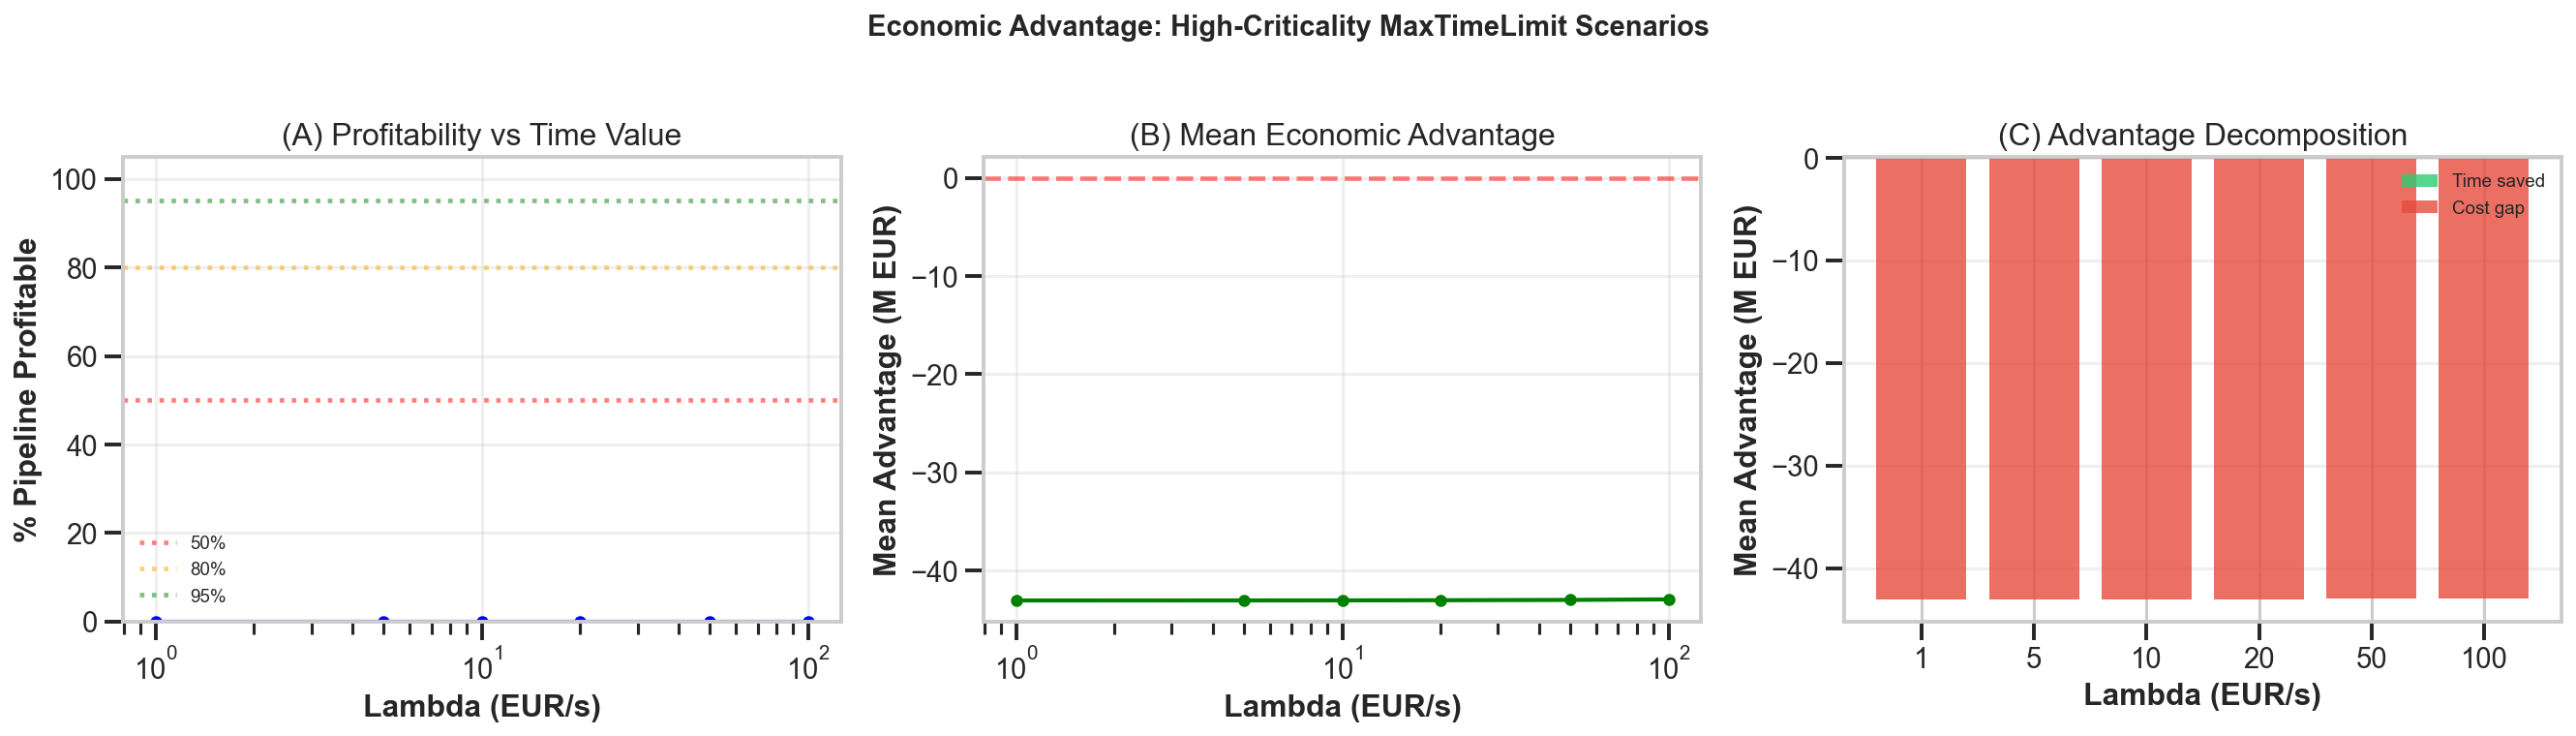

ECONOMIC ADVANTAGE: High-Crit MaxTimeLimit (n=41)
Breakeven lambda (50% profitable): inf EUR/s
Breakeven lambda (80% profitable): inf EUR/s
Breakeven lambda (95% profitable): inf EUR/s

At selected lambda values:
  lambda=   1 EUR/s:   0.0% profitable, mean advantage=-43.05 MEUR
  lambda=  10 EUR/s:   0.0% profitable, mean advantage=-43.04 MEUR
  lambda= 100 EUR/s:   0.0% profitable, mean advantage=-42.93 MEUR
  lambda=  20 EUR/s:   0.0% profitable, mean advantage=-43.02 MEUR
  lambda=   5 EUR/s:   0.0% profitable, mean advantage=-43.04 MEUR
  lambda=  50 EUR/s:   0.0% profitable, mean advantage=-42.99 MEUR


In [ ]:
# Economic Advantage (HTL subset)
if len(df_htl):
    econ_htl = EconomicAdvantageAnalyzer(df_htl)
    lambda_values_htl = [1, 5, 10, 20, 50, 100]
    sens_htl = econ_htl.sensitivity_analysis(lambda_values=lambda_values_htl)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    ax = axes[0]
    ax.plot(sens_htl['lambda'], sens_htl['pct_profitable'], 'b-o', lw=2, markersize=5)
    ax.axhline(50, color='red', linestyle=':', alpha=0.5, label='50%')
    ax.axhline(80, color='orange', linestyle=':', alpha=0.5, label='80%')
    ax.axhline(95, color='green', linestyle=':', alpha=0.5, label='95%')
    ax.set_xlabel('Lambda (EUR/s)', fontweight='bold')
    ax.set_ylabel('% Pipeline Profitable', fontweight='bold')
    ax.set_title('(A) Profitability vs Time Value'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 105); ax.set_xscale('log')

    ax = axes[1]
    ax.plot(sens_htl['lambda'], sens_htl['mean_advantage'] / 1e6, 'g-o', lw=2, markersize=5)
    ax.axhline(0, color='red', linestyle='--', alpha=0.5)
    ax.set_xlabel('Lambda (EUR/s)', fontweight='bold')
    ax.set_ylabel('Mean Advantage (M EUR)', fontweight='bold')
    ax.set_title('(B) Mean Economic Advantage'); ax.grid(True, alpha=0.3); ax.set_xscale('log')

    ax = axes[2]
    for lam in lambda_values_htl:
        adv_df = econ_htl.compute_advantage(lam)
        valid = adv_df.dropna(subset=['advantage'])
        if not len(valid):
            continue
        time_component = valid['advantage_from_time'].mean() / 1e6
        cost_component = valid['advantage_from_cost'].mean() / 1e6
        ax.bar(f'{lam}', time_component, color='#2ecc71', alpha=0.8, label='Time saved' if lam == lambda_values_htl[0] else '')
        ax.bar(f'{lam}', cost_component, bottom=time_component, color='#e74c3c', alpha=0.8,
               label='Cost gap' if lam == lambda_values_htl[0] else '')
    ax.axhline(0, color='black', linestyle='-', lw=0.5)
    ax.set_xlabel('Lambda (EUR/s)', fontweight='bold')
    ax.set_ylabel('Mean Advantage (M EUR)', fontweight='bold')
    ax.set_title('(C) Advantage Decomposition'); ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')

    fig.suptitle('Economic Advantage: High-Criticality MaxTimeLimit Scenarios', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig11_htl_economic_advantage.png', dpi=300, bbox_inches='tight')
    plt.show()

    summary_htl = econ_htl.compute_summary(lambda_values=lambda_values_htl)
    print('=' * 70)
    print(f'ECONOMIC ADVANTAGE: High-Crit MaxTimeLimit (n={len(df_htl)})')
    print('=' * 70)
    print(f"Breakeven lambda (50% profitable): {summary_htl['breakeven_lambda_50pct']:.2f} EUR/s")
    print(f"Breakeven lambda (80% profitable): {summary_htl['breakeven_lambda_80pct']:.2f} EUR/s")
    print(f"Breakeven lambda (95% profitable): {summary_htl['breakeven_lambda_95pct']:.2f} EUR/s")
    print(f"\nAt selected lambda values:")
    for key, val in sorted(summary_htl.items()):
        if key.startswith('lambda_'):
            lam = key.replace('lambda_', '')
            print(f"  lambda={lam:>4s} EUR/s: {val['pct_profitable']:5.1f}% profitable, "
                  f"mean advantage={val['mean_advantage_eur']/1e6:+.2f} MEUR")

    df_htl.to_csv(OUTPUT_DIR / 'high_crit_timelimit_comparison.csv', index=False)


## 21. Hypothesis 1 -- Compute-Bounded Exploration

**Claim:** as the candidate pool size `K` grows, the best-of-`K` candidate
returned by the pipeline achieves a lower cost gap with MILP.

The best-of-K curve is computed on the **strictly accepted** projection
objectives (i.e. `all_objectives`, with `inf` for rejected candidates).

In [23]:
MAX_AVAILABLE_SAMPLES = max((len(rec.get('all_objectives', [])) for rec in pipeline_results), default=0)
BEST_OF_K_VALUES = [k for k in [1, 2, 3, 5, 10] if k <= MAX_AVAILABLE_SAMPLES]
if not BEST_OF_K_VALUES and MAX_AVAILABLE_SAMPLES:
    BEST_OF_K_VALUES = [MAX_AVAILABLE_SAMPLES]
print(f"Max available sampled candidates per scenario: {MAX_AVAILABLE_SAMPLES}")
print(f"Best-of-K grid: {BEST_OF_K_VALUES}")

candidate_pool_df = build_candidate_pool_frame(pipeline_results, df)
diversity_df = compute_solution_diversity_frame(pipeline_results, df)
bestofk_summary, bestofk_scenario = compute_best_of_k_curve(
    pipeline_results, df, k_values=BEST_OF_K_VALUES or [1],
)
kdiag_summary, kdiag_scenario = compute_k_sampling_diagnostics(
    pipeline_results, df, k_values=BEST_OF_K_VALUES or [1],
)
display(bestofk_summary.round(3))
display(kdiag_summary.round(3))


Max available sampled candidates per scenario: 5
Best-of-K grid: [1, 2, 3, 5]


,k,n_scenarios,mean_cost_gap_pct,median_cost_gap_pct,mean_abs_cost_gap_pct,median_abs_cost_gap_pct,mean_gain_vs_k1_pct_milp,pct_pipeline_faster_than_milp,pct_beats_heuristic,mean_total_time_s,median_total_time_s,mean_speedup_vs_milp,median_speedup_vs_milp
0,1,300,108.391,4.652,108.391,4.652,0.0,84.667,75.661,24.318,12.398,5.834,1.672
1,2,272,100.270,3.499,100.270,3.499,inf,35.662,78.307,28.992,21.947,2.705,0.792
2,3,259,94.362,1.552,94.362,1.552,inf,23.166,82.022,35.876,31.663,1.724,0.522
3,5,232,77.742,0.783,77.742,0.783,inf,9.052,90.132,46.067,41.467,0.682,0.299


,k,n_scenarios,mean_hamming,mean_activation_rate,mean_energy_std,mean_best_cost_gap_pct,median_best_cost_gap_pct,mean_best_abs_cost_gap_pct,median_best_abs_cost_gap_pct,mean_best_slack_mwh,median_best_slack_mwh,mode_best_stage_reached
0,1,300,0.000,0.033,0.000,108.391,4.652,108.391,4.652,1938.526,0.0,repair_1000_flips
1,2,272,0.025,0.034,2.896,100.270,3.499,100.270,3.499,2430.703,0.0,repair_1000_flips
2,3,259,0.024,0.033,3.951,94.362,1.552,94.362,1.552,2795.063,0.0,repair_1000_flips
3,5,232,0.025,0.034,4.739,77.742,0.783,77.742,0.783,3544.813,0.0,hard_fix


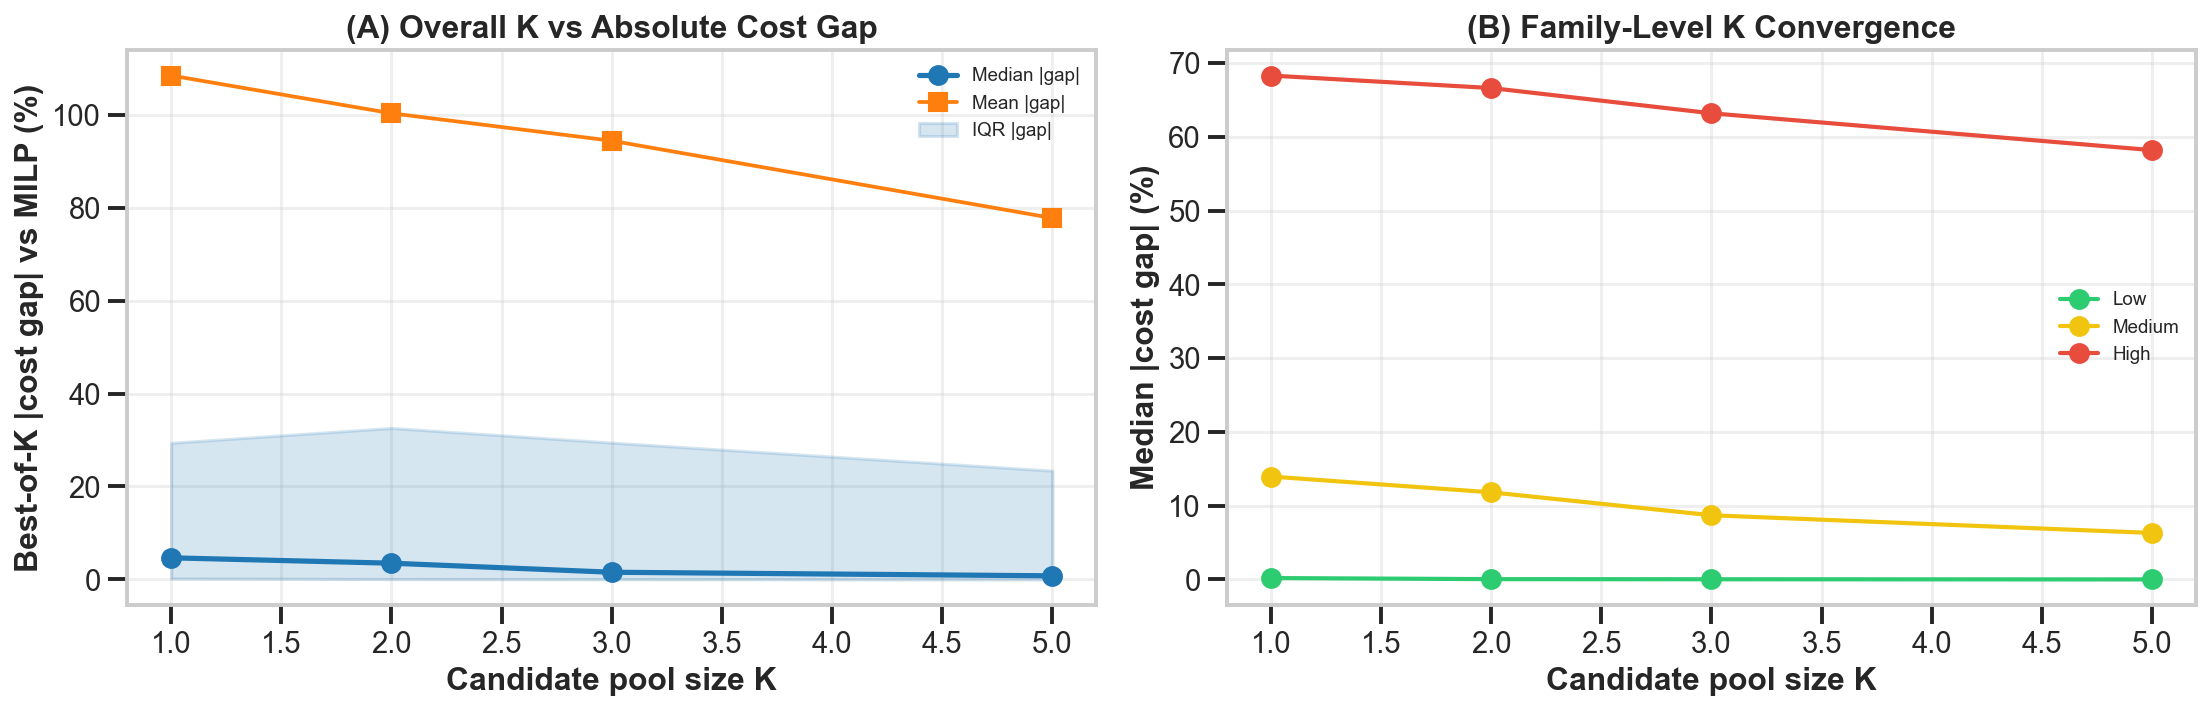

Hypothesis H1 diagnostics:
  base_k: 1
  top_k: 5
  n_paired: 182
  wilcoxon_stat: 55.0
  wilcoxon_pvalue_one_sided: 3.564815030717716e-24
  improvement_rate_pct: 96.7032967032967
  median_abs_gap_reduction_pct: 0.244515352082919
  mean_abs_gap_reduction_pct: 12.860432259461554
  friedman_stat: 262.07224334600727
  friedman_pvalue: 1.6015251956183399e-56
  friedman_k_values: [1, 2, 3, 5]
  friedman_n_scenarios: 182
  Supported: True


,k,mean_abs_cost_gap_pct,median_abs_cost_gap_pct,p25_abs_cost_gap_pct,p75_abs_cost_gap_pct,mean_speedup_vs_milp,n_scenarios
0,1,108.391,4.652,0.205,29.394,5.834,100
1,2,100.270,3.499,0.093,32.590,2.705,100
2,3,94.362,1.552,0.044,29.434,1.724,100
3,5,77.742,0.783,0.007,23.408,0.682,100


In [24]:
h1_stats = {}
H1_SUPPORTED = False
h1_pivot = pd.DataFrame()

if len(bestofk_scenario):
    h1_df = bestofk_scenario.copy()
    h1_df['abs_cost_gap_pct'] = h1_df['cost_gap_pct'].abs()

    gap_curve = (
        h1_df.groupby('k')
        .agg(
            mean_abs_cost_gap_pct=('abs_cost_gap_pct', 'mean'),
            median_abs_cost_gap_pct=('abs_cost_gap_pct', 'median'),
            p25_abs_cost_gap_pct=('abs_cost_gap_pct', lambda s: float(np.percentile(s.dropna(), 25)) if len(s.dropna()) else np.nan),
            p75_abs_cost_gap_pct=('abs_cost_gap_pct', lambda s: float(np.percentile(s.dropna(), 75)) if len(s.dropna()) else np.nan),
            mean_speedup_vs_milp=('speedup_vs_milp', 'mean'),
            n_scenarios=('scenario_id', 'nunique'),
        )
        .reset_index()
    )
    family_gap_curve = (
        h1_df.groupby(['family', 'k'])
        .agg(median_abs_cost_gap_pct=('abs_cost_gap_pct', 'median'),
             mean_abs_cost_gap_pct=('abs_cost_gap_pct', 'mean'))
        .reset_index()
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ax = axes[0]
    ax.plot(gap_curve['k'], gap_curve['median_abs_cost_gap_pct'], marker='o', lw=2.5, color='#1f77b4', label='Median |gap|')
    ax.plot(gap_curve['k'], gap_curve['mean_abs_cost_gap_pct'], marker='s', lw=1.8, color='#ff7f0e', label='Mean |gap|')
    ax.fill_between(gap_curve['k'], gap_curve['p25_abs_cost_gap_pct'], gap_curve['p75_abs_cost_gap_pct'],
                    alpha=0.18, color='#1f77b4', label='IQR |gap|')
    ax.set_xlabel('Candidate pool size K', fontweight='bold')
    ax.set_ylabel('Best-of-K |cost gap| vs MILP (%)', fontweight='bold')
    ax.set_title('(A) Overall K vs Absolute Cost Gap', fontweight='bold')
    ax.grid(True, alpha=0.3); ax.legend(fontsize=9)

    ax = axes[1]
    for fam in ['low', 'medium', 'high']:
        fam_dfk = family_gap_curve[family_gap_curve['family'] == fam]
        if len(fam_dfk) == 0:
            continue
        ax.plot(fam_dfk['k'], fam_dfk['median_abs_cost_gap_pct'], marker='o', lw=2,
                color=FAMILY_COLORS.get(fam), label=fam.capitalize())
    ax.set_xlabel('Candidate pool size K', fontweight='bold')
    ax.set_ylabel('Median |cost gap| (%)', fontweight='bold')
    ax.set_title('(B) Family-Level K Convergence', fontweight='bold')
    ax.grid(True, alpha=0.3); ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_h1_k_vs_cost_gap.png', dpi=300, bbox_inches='tight')
    plt.show()

    h1_pivot = h1_df.pivot_table(
        index=['family', 'scenario_id'], columns='k', values='abs_cost_gap_pct', aggfunc='first',
    )

    if BEST_OF_K_VALUES:
        base_k = min(BEST_OF_K_VALUES); top_k = max(BEST_OF_K_VALUES)
        paired = (h1_pivot[[base_k, top_k]].dropna()
                  if base_k in h1_pivot.columns and top_k in h1_pivot.columns else pd.DataFrame())
        if len(paired) >= 2:
            w_stat, w_p = wilcoxon(paired[top_k], paired[base_k], alternative='less', zero_method='wilcox')
            h1_stats.update({
                'base_k': int(base_k), 'top_k': int(top_k), 'n_paired': int(len(paired)),
                'wilcoxon_stat': float(w_stat), 'wilcoxon_pvalue_one_sided': float(w_p),
                'improvement_rate_pct': float((paired[top_k] <= paired[base_k]).mean() * 100),
                'median_abs_gap_reduction_pct': float((paired[base_k] - paired[top_k]).median()),
                'mean_abs_gap_reduction_pct': float((paired[base_k] - paired[top_k]).mean()),
            })
        complete_cols = [k for k in BEST_OF_K_VALUES if k in h1_pivot.columns]
        if len(complete_cols) >= 3:
            complete = h1_pivot[complete_cols].dropna()
            if len(complete) >= 2:
                friedman_stat, friedman_p = friedmanchisquare(*[complete[k].values for k in complete_cols])
                h1_stats['friedman_stat'] = float(friedman_stat)
                h1_stats['friedman_pvalue'] = float(friedman_p)
                h1_stats['friedman_k_values'] = [int(k) for k in complete_cols]
                h1_stats['friedman_n_scenarios'] = int(len(complete))

    print('Hypothesis H1 diagnostics:')
    for key, value in h1_stats.items():
        print(f"  {key}: {value}")

    H1_SUPPORTED = bool(
        h1_stats.get('improvement_rate_pct', 0.0) >= 50.0
        and h1_stats.get('wilcoxon_pvalue_one_sided', 1.0) < 0.05
    )
    print(f"  Supported: {H1_SUPPORTED}")
    display(gap_curve.round(3))
else:
    print('Best-of-K scenario table is empty. Re-run with n_samples >= 2 to test Hypothesis 1.')


## 22. H1 -- Oracle vs Strict + Fixed-Cohort Bottleneck Test

If we re-score candidates ex post using the **raw** projection objective
(`all_objectives_raw`, including candidates that were later rejected by the
strict accept/reject rule), does the best-of-K curve become cleaner?

If yes, the sampler is producing useful proposals and the bottleneck lies in
strict selection. The **fixed-cohort** restriction (only scenarios that have a
valid value at every K) makes the curves directly comparable across K.

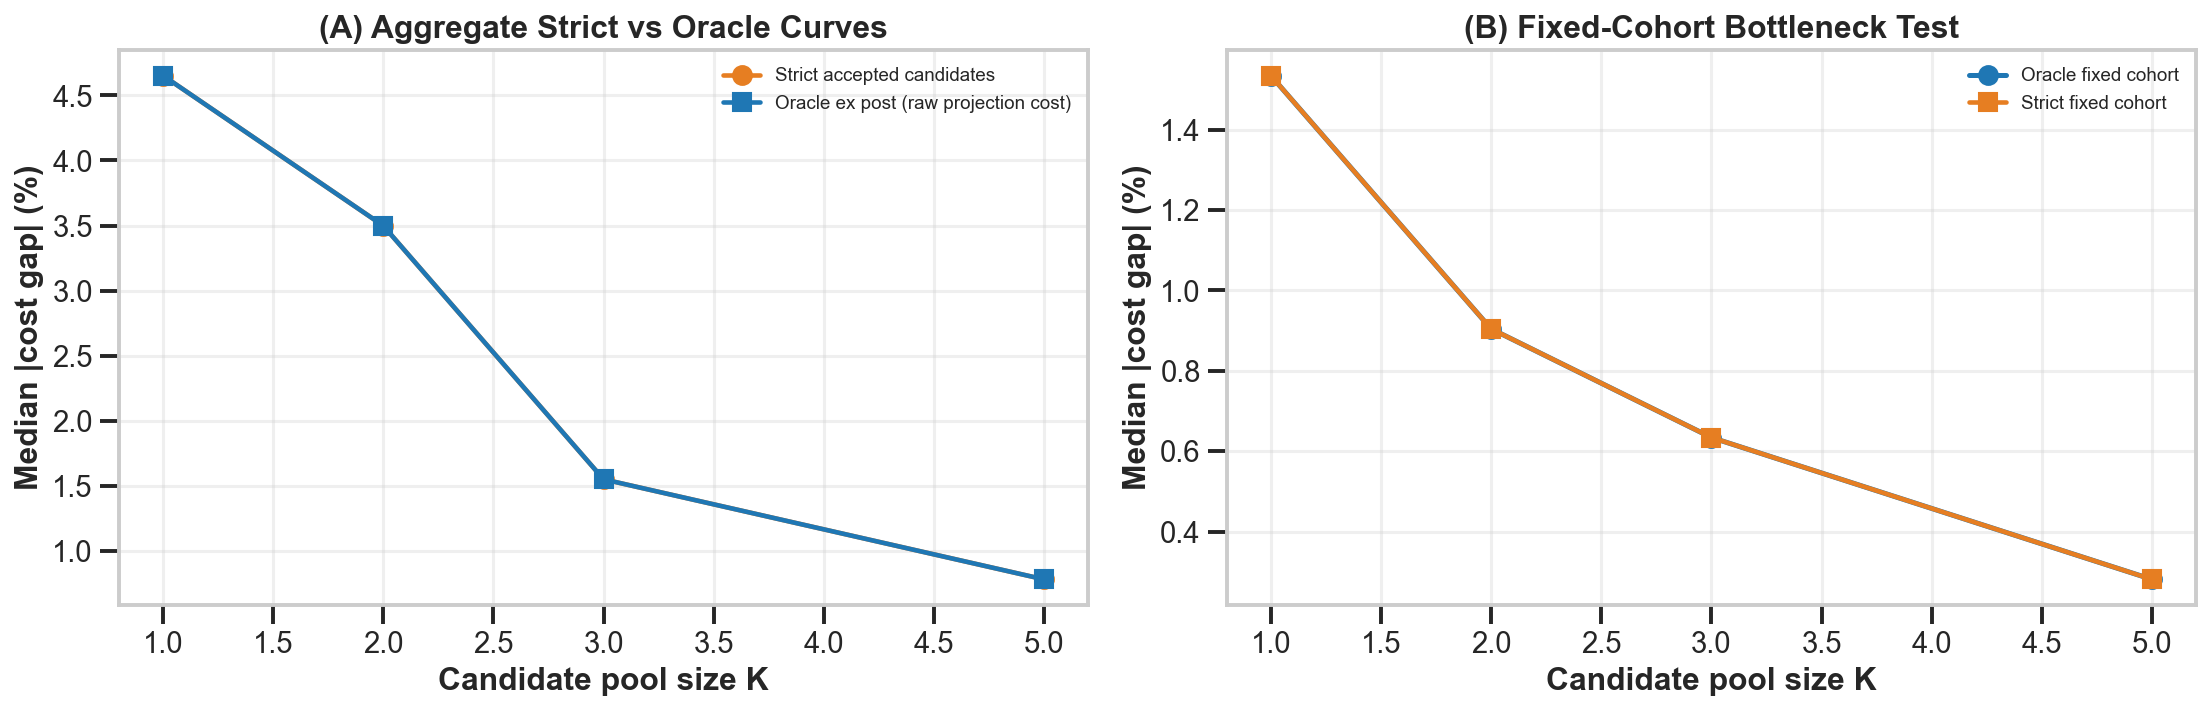

,k,n_scenarios,mean_cost_gap_pct,median_cost_gap_pct,mean_abs_cost_gap_pct,median_abs_cost_gap_pct,mean_gain_vs_k1_pct_milp,pct_pipeline_faster_than_milp,pct_beats_heuristic,mean_total_time_s,median_total_time_s,mean_speedup_vs_milp,median_speedup_vs_milp
0,1,300,108.391,4.652,108.391,4.652,0.0,84.667,75.661,24.318,12.398,5.834,1.672
1,2,272,100.270,3.499,100.270,3.499,inf,35.662,78.307,28.992,21.947,2.705,0.792
2,3,259,94.362,1.552,94.362,1.552,inf,23.166,82.022,35.876,31.663,1.724,0.522
3,5,232,77.742,0.783,77.742,0.783,inf,9.052,90.132,46.067,41.467,0.682,0.299


,k,n_scenarios_fixed_cohort,median_abs_cost_gap_pct,mean_abs_cost_gap_pct
0,1,182,1.535,42.989
1,2,182,0.904,36.037
2,3,182,0.634,33.124
3,5,182,0.281,30.129


,k,median_abs_cost_gap_pct_strict,mean_abs_cost_gap_pct_strict,median_abs_cost_gap_pct_oracle,mean_abs_cost_gap_pct_oracle,median_abs_gap_selector_loss_pct,mean_abs_gap_selector_loss_pct
0,1,4.652,108.391,4.652,108.391,0.0,0.0
1,2,3.499,100.270,3.499,100.270,0.0,0.0
2,3,1.552,94.362,1.552,94.362,0.0,0.0
3,5,0.783,77.742,0.783,77.742,0.0,0.0


Selector bottleneck diagnostics:
  base_k: 1
  top_k: 5
  n_paired: 182
  strict_h1_improvement_rate_pct: 96.7032967032967
  strict_h1_median_abs_gap_reduction_pct: 0.244515352082919
  oracle_improvement_rate_pct: 96.7032967032967
  oracle_median_abs_gap_reduction_pct: 0.244515352082919
  oracle_mean_abs_gap_reduction_pct: 12.860432259461554
  oracle_wilcoxon_stat: 55.0
  oracle_wilcoxon_pvalue_one_sided: 3.564815030717716e-24
  oracle_fixed_cohort_k_values: [1, 2, 3, 5]
  selector_loss_median_abs_gap_pct_at_top_k: 0.0


In [25]:
oracle_bestofk_summary, oracle_bestofk_scenario = compute_best_of_k_curve(
    pipeline_results, df, k_values=BEST_OF_K_VALUES or [1], objective_field='all_objectives_raw',
)

selector_bottleneck_summary = {}
oracle_fixed_cohort_summary = pd.DataFrame()
selector_loss_curve = pd.DataFrame()

if len(oracle_bestofk_scenario):
    oracle_h1_df = oracle_bestofk_scenario.copy()
    oracle_h1_df['abs_cost_gap_pct'] = oracle_h1_df['cost_gap_pct'].abs()

    oracle_pivot = oracle_h1_df.pivot_table(
        index=['family', 'scenario_id'], columns='k', values='abs_cost_gap_pct', aggfunc='first',
    )
    oracle_cols = [k for k in BEST_OF_K_VALUES if k in oracle_pivot.columns]
    oracle_complete = oracle_pivot[oracle_cols].dropna() if oracle_cols else pd.DataFrame()

    oracle_fixed_rows = []
    for k in oracle_cols:
        vals = oracle_complete[k].dropna()
        oracle_fixed_rows.append({
            'k': int(k),
            'n_scenarios_fixed_cohort': int(len(vals)),
            'median_abs_cost_gap_pct': float(vals.median()) if len(vals) else np.nan,
            'mean_abs_cost_gap_pct':   float(vals.mean())   if len(vals) else np.nan,
        })
    oracle_fixed_cohort_summary = pd.DataFrame(oracle_fixed_rows)

    if len(oracle_complete) and len(oracle_cols) >= 2:
        base_k = int(min(oracle_cols)); top_k = int(max(oracle_cols))
        paired = oracle_complete[[base_k, top_k]].dropna()
        if len(paired) >= 2:
            w_stat, w_p = wilcoxon(paired[top_k], paired[base_k], alternative='less', zero_method='wilcox')
            selector_bottleneck_summary = {
                'base_k': base_k, 'top_k': top_k, 'n_paired': int(len(paired)),
                'strict_h1_improvement_rate_pct': float(h1_stats.get('improvement_rate_pct', np.nan)),
                'strict_h1_median_abs_gap_reduction_pct': float(h1_stats.get('median_abs_gap_reduction_pct', np.nan)),
                'oracle_improvement_rate_pct': float((paired[top_k] <= paired[base_k]).mean() * 100.0),
                'oracle_median_abs_gap_reduction_pct': float((paired[base_k] - paired[top_k]).median()),
                'oracle_mean_abs_gap_reduction_pct': float((paired[base_k] - paired[top_k]).mean()),
                'oracle_wilcoxon_stat': float(w_stat),
                'oracle_wilcoxon_pvalue_one_sided': float(w_p),
                'oracle_fixed_cohort_k_values': [int(k) for k in oracle_cols],
            }

    if len(bestofk_summary) and len(oracle_bestofk_summary):
        selector_loss_curve = bestofk_summary[['k', 'median_abs_cost_gap_pct', 'mean_abs_cost_gap_pct']].merge(
            oracle_bestofk_summary[['k', 'median_abs_cost_gap_pct', 'mean_abs_cost_gap_pct']],
            on='k', how='inner', suffixes=('_strict', '_oracle'),
        )
        if len(selector_loss_curve):
            selector_loss_curve['median_abs_gap_selector_loss_pct'] = (
                selector_loss_curve['median_abs_cost_gap_pct_strict']
                - selector_loss_curve['median_abs_cost_gap_pct_oracle']
            )
            selector_loss_curve['mean_abs_gap_selector_loss_pct'] = (
                selector_loss_curve['mean_abs_cost_gap_pct_strict']
                - selector_loss_curve['mean_abs_cost_gap_pct_oracle']
            )
            if selector_bottleneck_summary:
                top_k_match = selector_loss_curve[selector_loss_curve['k'] == selector_bottleneck_summary.get('top_k')]
                if len(top_k_match):
                    selector_bottleneck_summary['selector_loss_median_abs_gap_pct_at_top_k'] = float(
                        top_k_match['median_abs_gap_selector_loss_pct'].iloc[0]
                    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    ax = axes[0]
    if len(bestofk_summary):
        ax.plot(bestofk_summary['k'], bestofk_summary['median_abs_cost_gap_pct'],
                marker='o', lw=2.2, color='#e67e22', label='Strict accepted candidates')
    if len(oracle_bestofk_summary):
        ax.plot(oracle_bestofk_summary['k'], oracle_bestofk_summary['median_abs_cost_gap_pct'],
                marker='s', lw=2.2, color='#1f77b4', label='Oracle ex post (raw projection cost)')
    ax.set_xlabel('Candidate pool size K', fontweight='bold')
    ax.set_ylabel('Median |cost gap| (%)', fontweight='bold')
    ax.set_title('(A) Aggregate Strict vs Oracle Curves', fontweight='bold')
    ax.grid(True, alpha=0.3); ax.legend(fontsize=9)

    ax = axes[1]
    if len(oracle_fixed_cohort_summary):
        ax.plot(oracle_fixed_cohort_summary['k'], oracle_fixed_cohort_summary['median_abs_cost_gap_pct'],
                marker='o', lw=2.4, color='#1f77b4', label='Oracle fixed cohort')
    if isinstance(h1_pivot, pd.DataFrame) and len(h1_pivot):
        strict_cols = [k for k in BEST_OF_K_VALUES if k in h1_pivot.columns]
        if strict_cols:
            strict_complete = h1_pivot[strict_cols].dropna()
            if len(strict_complete):
                strict_fixed_rows = []
                for k in strict_cols:
                    vals = strict_complete[k].dropna()
                    strict_fixed_rows.append({
                        'k': int(k),
                        'median_abs_cost_gap_pct': float(vals.median()) if len(vals) else np.nan,
                    })
                strict_fixed_df = pd.DataFrame(strict_fixed_rows)
                ax.plot(strict_fixed_df['k'], strict_fixed_df['median_abs_cost_gap_pct'],
                        marker='s', lw=2.2, color='#e67e22', label='Strict fixed cohort')
    ax.set_xlabel('Candidate pool size K', fontweight='bold')
    ax.set_ylabel('Median |cost gap| (%)', fontweight='bold')
    ax.set_title('(B) Fixed-Cohort Bottleneck Test', fontweight='bold')
    ax.grid(True, alpha=0.3); ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_h1_oracle_selector_bottleneck.png', dpi=300, bbox_inches='tight')
    plt.show()

    display(oracle_bestofk_summary.round(3))
    display(oracle_fixed_cohort_summary.round(3))
    if len(selector_loss_curve):
        display(selector_loss_curve.round(3))

    print('Selector bottleneck diagnostics:')
    for key, value in selector_bottleneck_summary.items():
        print(f"  {key}: {value}")
else:
    print('Oracle best-of-K table is empty. Re-run with cached raw candidate objectives.')


## 23. Projection and Repair Diagnostics

How often are sampled candidates already strictly feasible after `hard_fix`?
How aggressive are the repairs that succeed?

In [26]:
def _flatten_numeric_lists(series):
    values = []
    for item in series:
        if item is None:
            continue
        if isinstance(item, float) and np.isnan(item):
            continue
        if not isinstance(item, (list, tuple, np.ndarray)):
            continue
        for value in item:
            try:
                value_f = float(value)
            except (TypeError, ValueError):
                continue
            if np.isfinite(value_f):
                values.append(value_f)
    return values

def _projection_diag_row(name, sub_df, family_key=None):
    total_samples = float(sub_df['n_samples'].sum()) if 'n_samples' in sub_df.columns else 0.0
    total_direct = float(sub_df['pipeline_direct_feasible_count'].sum()) if 'pipeline_direct_feasible_count' in sub_df.columns else 0.0
    total_repaired = float(sub_df['pipeline_repaired_feasible_count'].sum()) if 'pipeline_repaired_feasible_count' in sub_df.columns else 0.0
    repair_attempts = max(total_samples - total_direct, 0.0)

    repair_flips = _flatten_numeric_lists(sub_df['pipeline_all_repair_flips']) if 'pipeline_all_repair_flips' in sub_df.columns else []
    repair_radii = _flatten_numeric_lists(sub_df['pipeline_all_repair_radii']) if 'pipeline_all_repair_radii' in sub_df.columns else []
    repair_times = _flatten_numeric_lists(sub_df['pipeline_all_repair_times']) if 'pipeline_all_repair_times' in sub_df.columns else []

    repaired_selected = (
        sub_df[sub_df['pipeline_best_status'] == 'repaired_feasible'].copy()
        if 'pipeline_best_status' in sub_df.columns
        else sub_df.iloc[0:0].copy()
    )

    k_min = k_max = k1_abs_gap = ktop_abs_gap = np.nan
    if len(bestofk_scenario):
        scope = bestofk_scenario if family_key is None else bestofk_scenario[bestofk_scenario['family'] == family_key]
        if len(scope):
            k_min = int(scope['k'].min()); k_max = int(scope['k'].max())
            k1_abs_gap = float(scope.loc[scope['k'] == k_min, 'cost_gap_pct'].abs().median())
            ktop_abs_gap = float(scope.loc[scope['k'] == k_max, 'cost_gap_pct'].abs().median())

    fallback_rate_pct = (
        float(sub_df['pipeline_fallback_used'].mean() * 100.0)
        if 'pipeline_fallback_used' in sub_df.columns and len(sub_df)
        else 0.0
    )
    failure_rate_pct = float((~sub_df['success'].astype(bool)).mean() * 100.0) if len(sub_df) else np.nan

    return {
        'Family': name,
        'N scenarios': int(len(sub_df)),
        'direct_feasible_rate_pct':  float(100.0 * total_direct / total_samples) if total_samples > 0 else np.nan,
        'repair_success_rate_pct':   float(100.0 * total_repaired / repair_attempts) if repair_attempts > 0 else np.nan,
        'pipeline_failure_rate_pct': failure_rate_pct,
        'fallback_rate_pct':         fallback_rate_pct,
        'mean_repair_flips':         float(np.mean(repair_flips))   if repair_flips else np.nan,
        'median_repair_flips':       float(np.median(repair_flips)) if repair_flips else np.nan,
        'median_repair_radius_used': float(np.median(repair_radii)) if repair_radii else np.nan,
        'median_repair_time_s':      float(np.median(repair_times)) if repair_times else np.nan,
        'best_of_K_abs_gap_pct_median': float(sub_df['cost_gap_pct'].abs().median()) if len(sub_df) else np.nan,
        'gap_k_min': k_min, 'gap_k_max': k_max,
        'abs_gap_pct_at_k_min_median': k1_abs_gap,
        'abs_gap_pct_at_k_max_median': ktop_abs_gap,
        'abs_gap_reduction_kmin_to_kmax_pct': float(k1_abs_gap - ktop_abs_gap) if np.isfinite(k1_abs_gap) and np.isfinite(ktop_abs_gap) else np.nan,
        'selected_repaired_flips_median':  float(repaired_selected['pipeline_selected_repair_flips'].median())  if len(repaired_selected) and 'pipeline_selected_repair_flips' in repaired_selected.columns else np.nan,
        'selected_repaired_radius_median': float(repaired_selected['pipeline_selected_repair_radius_used'].median()) if len(repaired_selected) and 'pipeline_selected_repair_radius_used' in repaired_selected.columns else np.nan,
        'selected_repaired_time_median_s': float(repaired_selected['pipeline_selected_repair_time'].median())   if len(repaired_selected) and 'pipeline_selected_repair_time' in repaired_selected.columns else np.nan,
    }

projection_diag_rows = [_projection_diag_row('ALL', df, family_key=None)]
for fam in ['low', 'medium', 'high']:
    fam_df = df[df['family'] == fam].copy()
    if len(fam_df):
        projection_diag_rows.append(_projection_diag_row(fam.capitalize(), fam_df, family_key=fam))
projection_diagnostics_df = pd.DataFrame(projection_diag_rows)
display(projection_diagnostics_df.round(3))

projection_status_counts = (
    df['pipeline_best_status'].value_counts(dropna=False).to_dict()
    if 'pipeline_best_status' in df.columns else {}
)
projection_diagnostics_summary = {
    'best_status_distribution': projection_status_counts,
    'overall_direct_feasible_rate_pct': float(projection_diagnostics_df.loc[projection_diagnostics_df['Family'] == 'ALL', 'direct_feasible_rate_pct'].iloc[0]),
    'overall_repair_success_rate_pct':  float(projection_diagnostics_df.loc[projection_diagnostics_df['Family'] == 'ALL', 'repair_success_rate_pct'].iloc[0]),
    'overall_pipeline_failure_rate_pct': float(projection_diagnostics_df.loc[projection_diagnostics_df['Family'] == 'ALL', 'pipeline_failure_rate_pct'].iloc[0]),
}
print('Projection / repair diagnostics:')
for k, v in projection_diagnostics_summary.items():
    print(f"  {k}: {v}")


,Family,N scenarios,direct_feasible_rate_pct,repair_success_rate_pct,pipeline_failure_rate_pct,fallback_rate_pct,mean_repair_flips,median_repair_flips,median_repair_radius_used,median_repair_time_s,best_of_K_abs_gap_pct_median,gap_k_min,gap_k_max,abs_gap_pct_at_k_min_median,abs_gap_pct_at_k_max_median,abs_gap_reduction_kmin_to_kmax_pct,selected_repaired_flips_median,selected_repaired_radius_median,selected_repaired_time_median_s
0,ALL,300,34.763,60.563,37.0,0.0,80.165,59.0,NaN,14.013,20.343,1,5,4.652,0.783,3.869,78.5,NaN,14.523
1,Low,100,87.000,100.000,0.0,0.0,33.185,33.0,NaN,2.120,0.174,1,5,0.195,0.006,0.189,38.5,NaN,2.535
2,Medium,100,4.069,81.027,29.0,0.0,61.598,59.0,NaN,13.116,21.256,1,5,13.955,6.307,7.648,76.5,NaN,13.673
3,High,100,0.000,25.959,82.0,0.0,191.455,135.5,NaN,30.767,inf,1,5,68.327,58.214,10.113,283.5,NaN,39.389


Projection / repair diagnostics:
  best_status_distribution: {'projection_failed': 111, 'repaired_feasible': 96, 'direct_feasible': 93}
  overall_direct_feasible_rate_pct: 34.76263399693721
  overall_repair_success_rate_pct: 60.563380281690144
  overall_pipeline_failure_rate_pct: 37.0


## 24. Hypothesis 2 -- Scaling with Criticality

**Claim:** the pipeline speedup over MILP increases with the scenario
criticality index.

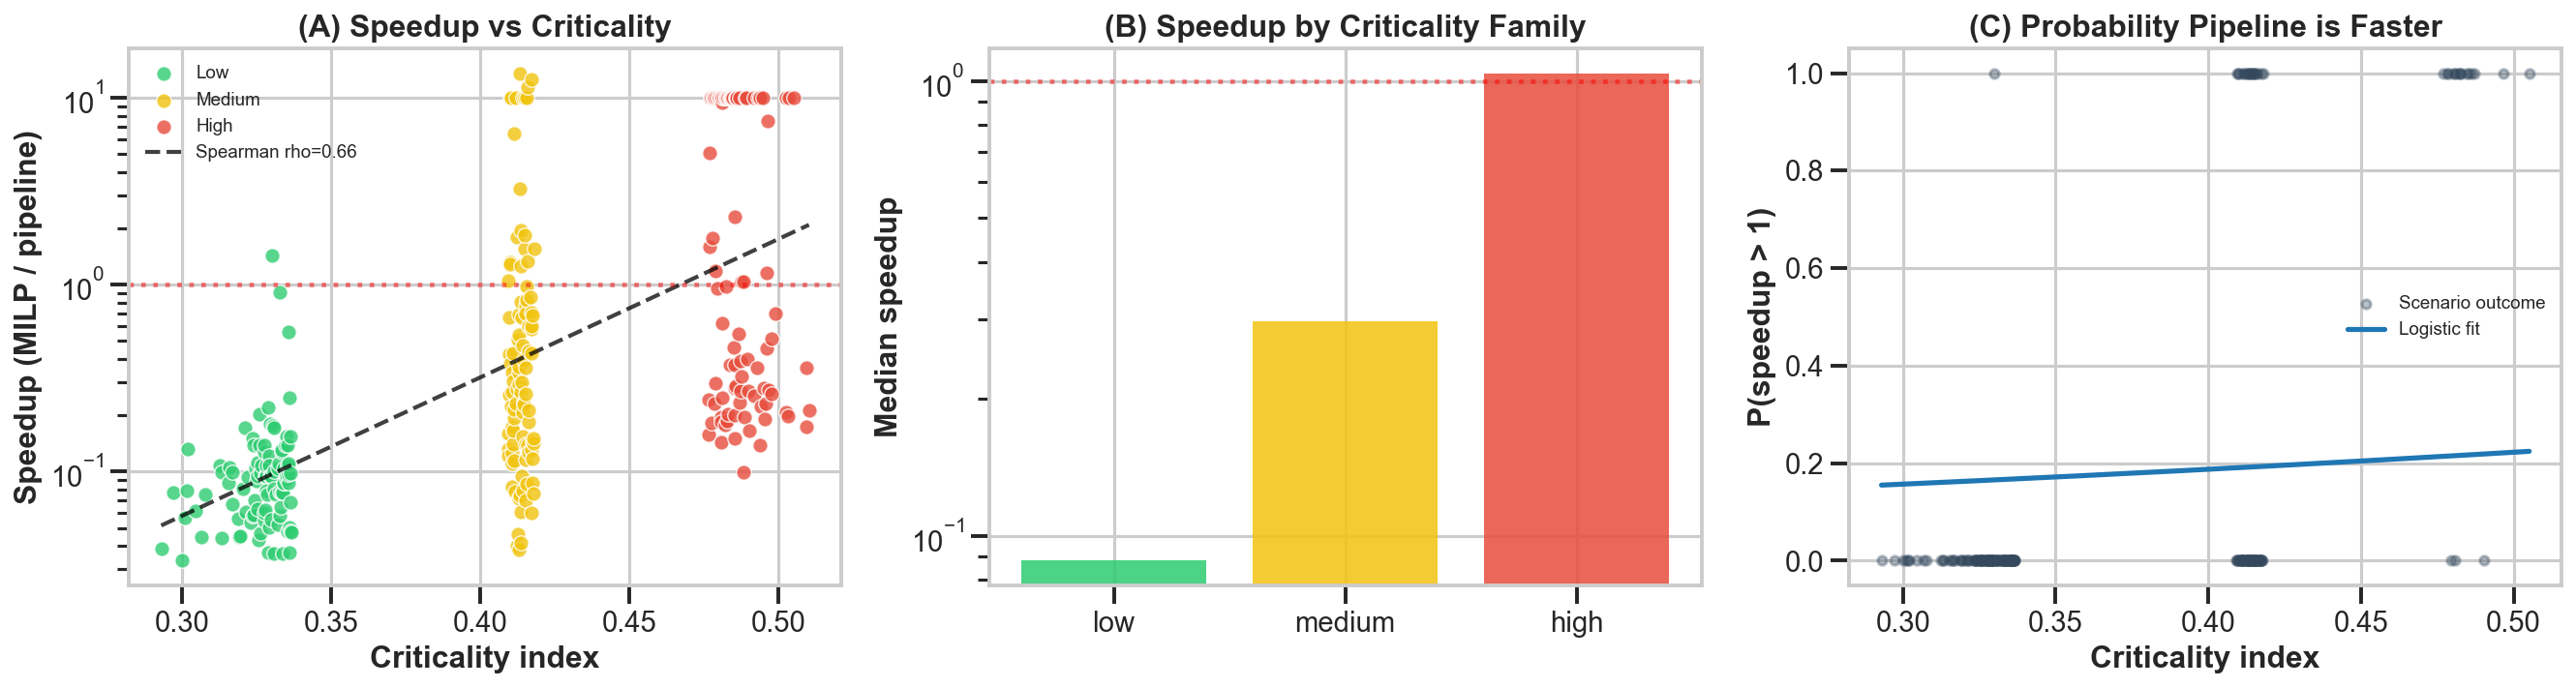

Hypothesis H2 diagnostics:
  spearman_rho_speedup_vs_criticality: 0.6644975035508364
  spearman_pvalue: 1.3804442179712322e-39
  loglinear_slope: 17.055472716647046
  loglinear_rvalue: 0.6325292156013541
  loglinear_pvalue: 6.247778782333775e-35
  pred_speedup_at_q10_criticality: 0.08901474283011901
  pred_speedup_at_q90_criticality: 1.4618157431568772
  pred_speedup_ratio_q90_over_q10: 16.422175660796917
  Supported: True


,feature,beta_log_speedup,beta_pipeline_faster_logit,beta_cost_gap_target,spearman_speedup_rho,spearman_speedup_pvalue,spearman_cost_gap_rho,spearman_cost_gap_pvalue
0,n_zones,1.5347,0.6000,681.0340,0.8361,0.0,0.6302,0.0
1,vre_volatility_index,-0.0946,-0.5982,42.4740,-0.6624,0.0,-0.5646,0.0
2,n_binary_variables,-0.4989,0.5966,-585.7915,0.8389,0.0,0.6384,0.0
3,storage_adequacy_hours,-0.0715,-0.3588,62.7685,-0.7072,0.0,-0.6692,0.0
4,peak_to_valley_ratio,0.1810,0.3506,147.3650,0.6791,0.0,0.6961,0.0


In [27]:
physical_feature_df = build_physical_complexity_frame(
    {name: paths['scenarios_dir'] for name, paths in FAMILIES.items()},
    cache_path=OUTPUT_DIR / 'physical_complexity_features.csv',
)
df_scaling = merge_physical_complexity_features(df, physical_feature_df)
scaling_models = fit_scaling_law_models(
    df_scaling, feature_col='criticality_index', cost_gap_col='cost_gap_pct', use_abs_gap=True,
)
physical_robustness_df = fit_physical_feature_robustness(
    df_scaling, feature_cols=PHYSICAL_FEATURE_COLUMNS, cost_gap_col='cost_gap_pct', use_abs_gap=True,
)

valid_speed = (
    df_scaling[['criticality_index', 'speedup', 'cost_gap_pct', 'family']]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=['criticality_index', 'speedup'])
)
valid_speed = valid_speed[valid_speed['speedup'] > 0]

rho_speed, p_speed = stats.spearmanr(valid_speed['criticality_index'], valid_speed['speedup'], nan_policy='omit')
lin_speed = stats.linregress(valid_speed['criticality_index'], np.log(valid_speed['speedup']))

crit_q10, crit_q90 = np.percentile(valid_speed['criticality_index'], [10, 90])
pred_speed_q10 = float(np.exp(lin_speed.intercept + lin_speed.slope * crit_q10))
pred_speed_q90 = float(np.exp(lin_speed.intercept + lin_speed.slope * crit_q90))

h2_stats = {
    'spearman_rho_speedup_vs_criticality': float(rho_speed),
    'spearman_pvalue': float(p_speed),
    'loglinear_slope': float(lin_speed.slope),
    'loglinear_rvalue': float(lin_speed.rvalue),
    'loglinear_pvalue': float(lin_speed.pvalue),
    'pred_speedup_at_q10_criticality': pred_speed_q10,
    'pred_speedup_at_q90_criticality': pred_speed_q90,
    'pred_speedup_ratio_q90_over_q10': float(pred_speed_q90 / max(pred_speed_q10, 1e-9)),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
for fam in ['low', 'medium', 'high']:
    sub = valid_speed[valid_speed['family'] == fam]
    ax.scatter(sub['criticality_index'], sub['speedup'], c=FAMILY_COLORS[fam],
               s=55, alpha=0.8, edgecolors='white', linewidth=0.7, label=fam.capitalize())
x_line = np.linspace(valid_speed['criticality_index'].min(), valid_speed['criticality_index'].max(), 200)
y_line = np.exp(lin_speed.intercept + lin_speed.slope * x_line)
ax.plot(x_line, y_line, 'k--', lw=2, alpha=0.75, label=f"Spearman rho={rho_speed:.2f}")
ax.axhline(1.0, color='red', linestyle=':', alpha=0.5)
ax.set_yscale('log')
ax.set_xlabel('Criticality index', fontweight='bold')
ax.set_ylabel('Speedup (MILP / pipeline)', fontweight='bold')
ax.set_title('(A) Speedup vs Criticality', fontweight='bold'); ax.legend(fontsize=9)

ax = axes[1]
family_speedup = (
    valid_speed.groupby('family')['speedup'].agg(['median', 'mean', 'count']).reindex(['low', 'medium', 'high'])
)
ax.bar(family_speedup.index, family_speedup['median'],
       color=[FAMILY_COLORS[f] for f in family_speedup.index], alpha=0.85)
ax.axhline(1.0, color='red', linestyle=':', alpha=0.5)
ax.set_yscale('log')
ax.set_ylabel('Median speedup', fontweight='bold')
ax.set_title('(B) Speedup by Criticality Family', fontweight='bold')

ax = axes[2]
if scaling_models:
    points = scaling_models['panel_b_points']
    fit = scaling_models['panel_b_fit']
    ax.scatter(points['criticality_index'], points['pipeline_faster'],
               s=20, alpha=0.35, color='#34495e', label='Scenario outcome')
    if len(fit):
        ax.plot(fit['criticality_index'], fit['prob_pipeline_faster'],
                color='#1f77b4', lw=2.5, label='Logistic fit')
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel('Criticality index', fontweight='bold')
    ax.set_ylabel('P(speedup > 1)', fontweight='bold')
    ax.set_title('(C) Probability Pipeline is Faster', fontweight='bold')
    ax.legend(fontsize=9)
else:
    ax.text(0.5, 0.5, 'Scaling model unavailable', ha='center', va='center'); ax.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_h2_speedup_vs_criticality.png', dpi=300, bbox_inches='tight')
plt.show()

print('Hypothesis H2 diagnostics:')
for key, value in h2_stats.items():
    print(f"  {key}: {value}")

H2_SUPPORTED = bool(rho_speed > 0 and p_speed < 0.05)
print(f"  Supported: {H2_SUPPORTED}")

display(physical_robustness_df.round(4))


## 25. Save All Outputs and Hypothesis Summary

In [28]:
hypothesis_summary = {
    'hypothesis_h1_compute_bounded_exploration_supported': bool(H1_SUPPORTED),
    'hypothesis_h2_speedup_scales_with_criticality_supported': bool(H2_SUPPORTED),
    'h1_stats': h1_stats,
    'selector_bottleneck_summary': selector_bottleneck_summary,
    'h2_stats': h2_stats,
    'projection_diagnostics_summary': projection_diagnostics_summary,
    'scaling_law_summary': scaling_models.get('summary', {}) if scaling_models else {},
    'config': {
        'ebm_checkpoint': str(EBM_CHECKPOINT_REL),
        'encoder_checkpoint': str(ENCODER_CHECKPOINT_REL),
        'lp_worker_max_stages': int(config.lp_worker_max_stages),
        'enable_exact_fallback': bool(config.enable_exact_fallback),
        'n_samples': int(config.n_samples),
        'flip_budget_repair_20': int(config.flip_budget_repair_20),
        'flip_budget_repair_100': int(config.flip_budget_repair_100),
    },
}

summary_table.to_csv(OUTPUT_DIR / 'summary_table.csv', index=False)
df.to_csv(OUTPUT_DIR / 'full_comparison.csv', index=False)
candidate_pool_df.to_csv(OUTPUT_DIR / 'candidate_pool_samples.csv', index=False)
diversity_df.to_csv(OUTPUT_DIR / 'solution_diversity.csv', index=False)
if 'projection_diagnostics_df' in globals() and len(projection_diagnostics_df):
    projection_diagnostics_df.to_csv(OUTPUT_DIR / 'projection_diagnostics_summary.csv', index=False)
if len(bestofk_summary):
    bestofk_summary.to_csv(OUTPUT_DIR / 'best_of_k_summary.csv', index=False)
if len(bestofk_scenario):
    bestofk_scenario.to_csv(OUTPUT_DIR / 'best_of_k_per_scenario.csv', index=False)
if len(oracle_bestofk_summary):
    oracle_bestofk_summary.to_csv(OUTPUT_DIR / 'oracle_best_of_k_summary.csv', index=False)
if len(oracle_bestofk_scenario):
    oracle_bestofk_scenario.to_csv(OUTPUT_DIR / 'oracle_best_of_k_per_scenario.csv', index=False)
if len(oracle_fixed_cohort_summary):
    oracle_fixed_cohort_summary.to_csv(OUTPUT_DIR / 'oracle_best_of_k_fixed_cohort_summary.csv', index=False)
if len(selector_loss_curve):
    selector_loss_curve.to_csv(OUTPUT_DIR / 'selector_loss_curve.csv', index=False)
if len(kdiag_summary):
    kdiag_summary.to_csv(OUTPUT_DIR / 'k_sampling_diagnostics_summary.csv', index=False)
if len(kdiag_scenario):
    kdiag_scenario.to_csv(OUTPUT_DIR / 'k_sampling_diagnostics_per_scenario.csv', index=False)
df_scaling.to_csv(OUTPUT_DIR / 'full_comparison_with_physical_features.csv', index=False)
if len(physical_robustness_df):
    physical_robustness_df.to_csv(OUTPUT_DIR / 'physical_feature_robustness.csv', index=False)

econ_summary = econ.compute_summary(lambda_values=[0.5, 1, 2, 5, 10, 20, 50, 100])
with open(OUTPUT_DIR / 'economic_summary.json', 'w') as f:
    json.dump(econ_summary, f, indent=2, default=str)
sensitivity_df.to_csv(OUTPUT_DIR / 'lambda_sensitivity.csv', index=False)
for fam_name, fam_sens_df in family_sens.items():
    fam_sens_df.to_csv(OUTPUT_DIR / f'lambda_sensitivity_{fam_name}.csv', index=False)

with open(OUTPUT_DIR / 'hypothesis_summary.json', 'w', encoding='utf-8') as f:
    json.dump(hypothesis_summary, f, indent=2, default=str)
with open(OUTPUT_DIR / 'eval_metrics.json', 'w', encoding='utf-8') as f:
    json.dump({k: v for k, v in eval_output.items() if k != 'dataframe'}, f, indent=2, default=str)

print(f"All outputs saved to: {OUTPUT_DIR}")
for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        size_kb = path.stat().st_size / 1024
        print(f"  {path.name:50s} {size_kb:9.1f} KB")

print("\nHypothesis verdicts:")
print(f"  H1 - cost gap decreases with K     : {H1_SUPPORTED}")
print(f"  H2 - speedup increases with crit.  : {H2_SUPPORTED}")


All outputs saved to: C:\Users\coudr\OneDrive\projects\benchmark\benchmark_milp_gnn\outputs\latent_time_budget_120_caps_k5
  best_of_k_per_scenario.csv                             164.0 KB
  best_of_k_summary.csv                                    1.0 KB
  candidate_pool_samples.csv                             595.5 KB
  economic_summary.json                                    1.4 KB
  eval_metrics.json                                        8.7 KB
  fig1_solve_time_cost_gap_speedup.png                   803.8 KB
  fig2_stage_distribution_speedup.png                    194.5 KB
  fig3_pareto_quality_speed.png                          258.5 KB
  fig4_economic_advantage.png                            207.9 KB
  fig5_lambda_heatmap.png                                111.9 KB
  fig6_cumulative_time.png                               285.4 KB
  fig7_timing_breakdown.png                              152.1 KB
  fig8_criticality_complexity.png                        445.8 KB
  fig9_htl_speed_an